# Spatial generalisation and survey-campaign confounding in machine-learning models for retrospective mapping of cattle disease occurrence in Ethiopia
**Executable notebook (22 sections).** Household-reported CBPP, FMD and LSD occurrence (ILRI MELDATA; 3,340 households, 462 locations, five survey campaigns, 2012-2019).

**What it does.** Every table and figure is computed from the raw data by the functions in `src/paper1/`. Each experiment writes a checkpoint under `results/`; if the checkpoint exists it is loaded, otherwise it is computed. Delete `results/paper1_v1`, `results/paper1_rev_v1` and `results/paper1_rev2_v1` to recompute everything. Inputs that are kept: the raw data, the fold file, the earlier 23-model library cache for the models that use no outcome-derived features (`results/stage4_v1`, `data/reference`), and the corrected-prior refits (`results/audit_v1/A5`).

**Scope.** Retrospective mapping of household-reported occurrence; not forecasting; not laboratory-confirmed. No optimisation or swarm algorithm is used in any analysis. `Weight_*`, `Year`, `Region`, `Year_region` and identifiers are never predictors (one library model uses year-region group sizes as training weights; see Section 10).

## 1. Library installation and imports
In Google Colab, upload `IJIES_Paper1_code_and_results.zip` and the three data files, then run this cell. Locally, install `requirements.txt` first.

In [1]:
import sys, os, subprocess, zipfile, json, platform, importlib, runpy, warnings
from pathlib import Path
if 'google.colab' in sys.modules:
    if Path('IJIES_Paper1_code_and_results.zip').exists() and not Path('IJIES_Paper1_code_and_results').exists():
        zipfile.ZipFile('IJIES_Paper1_code_and_results.zip').extractall('.')
    os.chdir('IJIES_Paper1_code_and_results')
    for f in ('cbpp.xlsx', 'fmd.xlsx', 'lsd.xlsx'):
        if Path('..', f).exists(): os.replace(Path('..', f), Path('data/raw', f))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src')); os.environ['PYTHONPATH'] = str(ROOT / 'src'); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings('ignore'); pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 60)
vers = {'python': platform.python_version()}
for m in ['numpy', 'pandas', 'scipy', 'sklearn', 'xgboost', 'lightgbm', 'catboost', 'shap', 'matplotlib']:
    try: vers[m] = importlib.import_module(m).__version__
    except ImportError: vers[m] = 'NOT INSTALLED'
print(json.dumps(vers, indent=1)); assert vers['shap'] != 'NOT INSTALLED', 'install shap (requirements.txt) for Section 15'
P1, REV, R2 = ROOT / 'results/paper1_v1', ROOT / 'results/paper1_rev_v1', ROOT / 'results/paper1_rev2_v1'
def check(cond, msg):
    if not cond: raise AssertionError(msg)
    print('OK -', msg)
def show(name, width=900):
    for f in (R2 / 'figures', REV / 'figures', P1 / 'figures'):
        p = f / f'{name}.png'
        if p.exists(): display(Image(filename=str(p), width=width)); return
    print('missing figure:', name)
def tab(path): return pd.read_csv(path)

{
 "python": "3.13.18",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scipy": "1.18.1",
 "sklearn": "1.9.1",
 "xgboost": "3.4.1",
 "lightgbm": "4.7.0",
 "catboost": "1.2.10",
 "shap": "0.54.1",
 "matplotlib": "3.11.2"
}


## 2. Dataset loading
The three disease files share household IDs, environmental variables, coordinates and the year-region code. `setup()` checks that these columns are identical across files, merges them, attaches the fixed fold file and projects coordinates to km.

In [2]:
from paper1.core import setup, dev_splits, DIS, FEATURE_SETS, auc
from common.data import AUDITED_MD5, file_hashes, BLOCK_KM
for f in AUDITED_MD5: check((ROOT / 'data/raw' / f).exists(), f'raw file present: {f}')
md5 = {f: file_hashes(ROOT / 'data/raw' / f)['md5'] for f in AUDITED_MD5}; check(md5 == AUDITED_MD5, 'raw-file MD5 hashes match the audited values')
df, Y, NB, FB = setup()
check(len(df) == 3340 and df['loc'].nunique() == 462, '3,340 households at 462 locations')
df[['ID', 'Location_id', 'Year', 'Region', 'Latitude', 'Longitude', 'Altitude', 'Temperature', 'Precipitation', 'Relative_humidity', 'Wind_speed'] + DIS].head()

OK - raw file present: cbpp.xlsx
OK - raw file present: fmd.xlsx
OK - raw file present: lsd.xlsx
OK - raw-file MD5 hashes match the audited values


OK - 3,340 households at 462 locations


,ID,Location_id,Year,Region,Latitude,Longitude,Altitude,Temperature,Precipitation,Relative_humidity,Wind_speed,CBPP,FMD,LSD
0,1,306,2019,Amhara,9.5,39.5,2827.598635,14.313302,1049.721300,69.635589,3.628753,0,1,0
1,2,306,2019,Amhara,9.5,39.5,2829.154368,14.309543,1050.008538,69.654977,3.630186,0,1,0
2,3,306,2019,Amhara,9.5,39.5,2828.849432,14.310440,1049.954755,69.655868,3.630246,0,0,0
3,4,306,2019,Amhara,9.5,39.5,2831.484012,14.303409,1050.404202,69.665001,3.630948,0,0,0
4,5,306,2019,Amhara,9.5,39.5,2829.951906,14.307300,1050.148716,69.655304,3.630223,0,1,0


## 3. Data quality assessment
Missing values, duplicates, coordinate consistency, outcome coding, and a flag for 2012 households labelled Afar but located south of 8 degrees N (kept as published; region is not a predictor).

In [3]:
pred = ['Altitude', 'Temperature', 'Precipitation', 'Relative_humidity', 'Wind_speed', 'Latitude', 'Longitude']
q = {'missing cells (predictors, outcomes, year, region)': int(df[pred + DIS + ['Year', 'Region']].isna().sum().sum()), 'duplicate household IDs': int(df.ID.duplicated().sum()),
     'duplicate rows (predictors + outcomes)': int(df.duplicated(pred + DIS).sum()), 'locations with >1 coordinate pair': int((df.groupby('loc')[['Latitude', 'Longitude']].nunique() > 1).any(axis=1).sum()),
     'outcome values other than 0/1': int((~df[DIS].isin([0, 1])).sum().sum()), 'locations surveyed in >1 year': int((df.groupby('loc').Year.nunique() > 1).sum()),
     '2012 Afar households south of 8 deg N (flag)': int(((df.Year == 2012) & (df.Region == 'Afar') & (df.Latitude < 8)).sum())}
display(pd.Series(q, name='count').to_frame())
check(q['missing cells (predictors, outcomes, year, region)'] == 0 and q['duplicate household IDs'] == 0 and q['outcome values other than 0/1'] == 0, 'no missing values, duplicate IDs or invalid outcomes')
pred_cols = pred; checks = {'missing cells (predictors + outcomes)': int(df[pred_cols + DIS].isna().sum().sum()), 'duplicate rows (predictors + outcomes)': int(df.duplicated(pred_cols + DIS).sum()),
          'locations with >1 coordinate pair': int((df.groupby('loc')[['Latitude', 'Longitude']].nunique() > 1).any(axis=1).sum()),
          'coordinate pairs shared by >1 location': int((df.groupby(['Latitude', 'Longitude'])['loc'].nunique() > 1).sum()),
          'locations in >1 81-km block (repeat 1)': int((df.groupby('loc').block_r1.nunique() > 1).sum()),
          'locations surveyed in >1 year': int((df.groupby('loc').Year.nunique() > 1).sum()),
          'latitude range': (float(df.Latitude.min()), float(df.Latitude.max())), 'longitude range': (float(df.Longitude.min()), float(df.Longitude.max()))}
(P1 / 'tables').mkdir(parents=True, exist_ok=True); pd.Series({k: str(v) for k, v in checks.items()}).to_csv(P1 / 'tables' / 'data_validation_report_v1.csv')

,count
"missing cells (predictors, outcomes, year, region)",0
duplicate household IDs,0
duplicate rows (predictors + outcomes),0
locations with >1 coordinate pair,0
outcome values other than 0/1,0
locations surveyed in >1 year,13
2012 Afar households south of 8 deg N (flag),10


OK - no missing values, duplicate IDs or invalid outcomes


## 4. Exploratory data analysis
Prevalence by survey year, overlap between diseases, environmental differences between positive and negative households, and survey campaigns (coverage, overlap and within-campaign spread).

,Survey year,Households,Locations,"CBPP positive, n (%)","FMD positive, n (%)","LSD positive, n (%)"
0,2012,224,73,86 (38.4),22 (9.8),45 (20.1)
1,2014,684,112,297 (43.4),132 (19.3),108 (15.8)
2,2015,656,106,225 (34.3),223 (34.0),228 (34.8)
3,2018,1341,161,138 (10.3),62 (4.6),100 (7.5)
4,2019,435,24,2 (0.5),172 (39.5),266 (61.1)
5,All,3340,462,748 (22.4),611 (18.3),747 (22.4)


household-level phi correlation between diseases


,CBPP,FMD,LSD
CBPP,1.000,-0.009,-0.025
FMD,-0.009,1.000,0.172
LSD,-0.025,0.172,1.000


,count,mean,std,min,25%,50%,75%,max
Altitude,3340.0,1662.62,706.15,-76.42,1083.42,1704.36,2133.95,3530.10
Temperature,3340.0,20.04,3.91,9.66,17.31,19.88,22.47,30.90
Precipitation,3340.0,1000.75,422.40,121.22,656.26,960.13,1285.89,1949.61
Relative_humidity,3340.0,62.78,6.91,43.59,57.59,63.66,68.55,80.63
Wind_speed,3340.0,2.72,0.78,0.97,2.09,2.81,3.21,5.66


,CBPP,FMD,LSD
Altitude,-0.552,-0.257,-0.330
Temperature,0.512,0.171,0.304
Precipitation,-0.540,-0.092,0.052
Relative_humidity,-0.485,0.019,-0.045
Wind_speed,0.457,0.140,-0.127


{
 "D1": {
  "locations_shared_between_train_and_test": 0,
  "blocks_shared": 0,
  "all_blocks_within_block_size": true,
  "min_test_to_train_km": 10.8,
  "median_test_to_train_km_range": [
   24.8,
   45.8
  ],
  "fold_households_range": [
   630,
   712
  ],
  "block_km": 80.94049315824638
 },
 "D2": {
  "inner_splits_checked": 75,
  "shared_blocks_or_outer_test_rows": 0
 },
 "D3": [
  {
   "disease": "CBPP",
   "max_diff_test_scores": 0.0,
   "max_diff_inner_oof": 0.0,
   "max_diff_calibrated": 0.0,
   "threshold_diff": 0.0
  },
  {
   "disease": "FMD",
   "max_diff_test_scores": 0.0,
   "max_diff_inner_oof": 0.0,
   "max_diff_calibrated": 0.0,
   "threshold_diff": 0.0
  },
  {
   "disease": "LSD",
   "max_diff_test_scores": 0.0,
   "max_diff_inner_oof": 0.0,
   "max_diff_calibrated": 0.0,
   "threshold_diff": 0.0
  }
 ],
 "D4": {
  "block_km_used": 80.94049315824638,
  "rule": "median of the three outcome practical ranges (run 1); equals the FMD range",
  "label_free_median_range_k

,Survey year,Households,Locations,Regions,Latitude range,Longitude range,Locations with another campaign within 81 km (%),Median distance to nearest other-campaign location (km),CBPP prevalence (%),CBPP location prevalence IQR (locations with >= 5 households),FMD prevalence (%),FMD location prevalence IQR (locations with >= 5 households),LSD prevalence (%),LSD location prevalence IQR (locations with >= 5 households)
0,2012,224,73,Afar,4.0 to 13.3,36.9 to 43.4,83.6,31.3,38.4,0.26 to 0.51,9.8,0.00 to 0.14,20.1,0.04 to 0.27
1,2014,684,112,"Oromia, SNNP",4.1 to 7.0,35.0 to 40.0,74.1,44.4,43.4,0.20 to 0.60,19.3,0.00 to 0.30,15.8,0.00 to 0.25
2,2015,656,106,"Afar, Oromia, SNNP, Somali",3.5 to 13.3,35.1 to 46.4,74.5,34.0,34.3,0.16 to 0.56,34.0,0.05 to 0.57,34.8,0.20 to 0.50
3,2018,1341,161,"Amhara, Benshangul, Gambela, Oromia, SNNP, Tigray",5.9 to 14.2,33.9 to 42.0,65.2,65.9,10.3,0.00 to 0.20,4.6,0.00 to 0.00,7.5,0.00 to 0.10
4,2019,435,24,"Amhara, Oromia",7.3 to 12.7,36.4 to 40.0,100.0,32.3,0.5,0.00 to 0.00,39.5,0.16 to 0.67,61.1,0.33 to 0.85


,disease,eta2_survey_year,eta2_location,eta2_region,eta2_location_within_year
0,CBPP,0.148,0.385,0.084,0.278
1,FMD,0.125,0.385,0.040,0.297
2,LSD,0.187,0.425,0.023,0.293


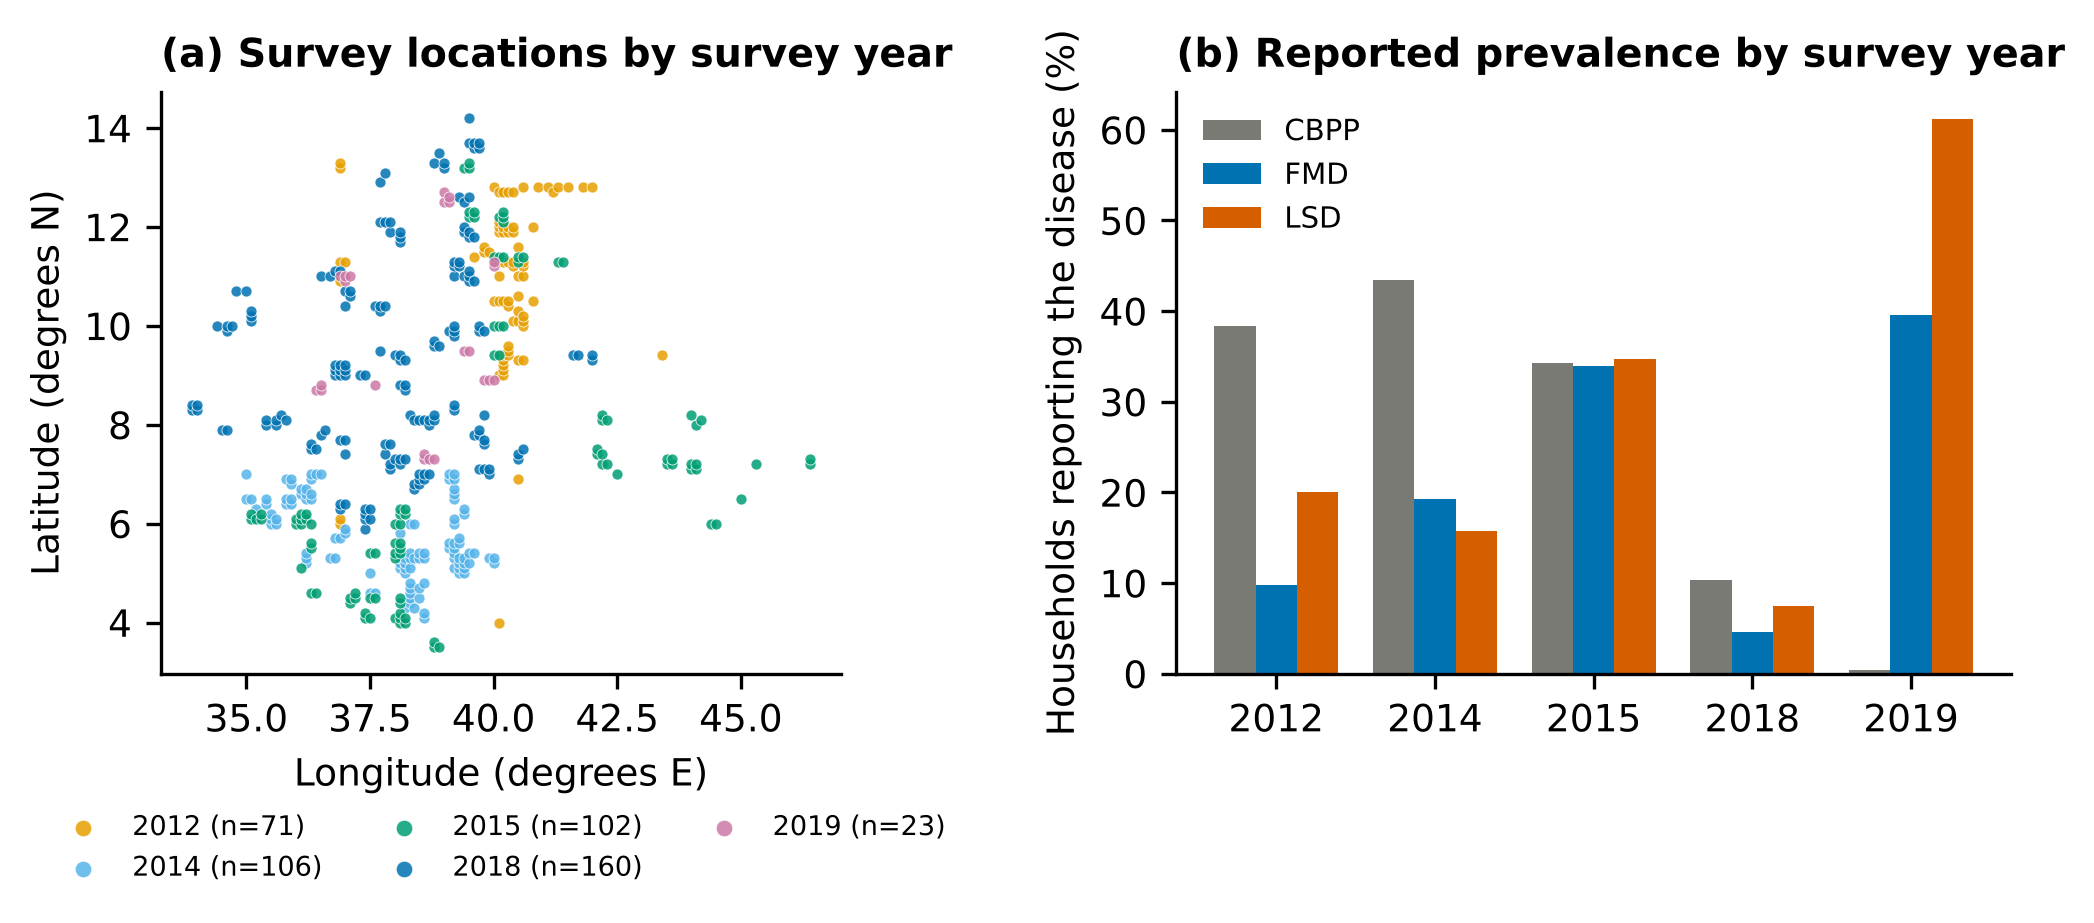

In [4]:
from paper1 import analysis as A
display(A.table1())
print('household-level phi correlation between diseases'); display(pd.DataFrame(np.corrcoef(Y.T), index=DIS, columns=DIS).round(3))
smd = pd.DataFrame({dn: [(df.loc[Y[:, d] == 1, v].mean() - df.loc[Y[:, d] == 0, v].mean()) / df[v].std() for v in pred[:5]] for d, dn in enumerate(DIS)}, index=pred[:5])
display(df[pred[:5]].describe().T.round(2)); display(smd.round(3))
from paper1 import experiments as X; X.e2_split(1, 0)   # the test-label isolation check (D3) compares against this checkpoint
runpy.run_path('src/paper1/rev_design_checks_v1.py', run_name='__main__')
display(tab(REV / 'design_checks/D5_campaign_descriptors_v1.csv')); display(tab(REV / 'design_checks/D5_variance_shares_v1.csv').round(3)); A.fig_years(); show('Fig2_survey_years_v2')

## 5. Preprocessing
No imputation is needed. Tree models use raw values; linear, distance and kernel models standardise inputs inside each training set. `Weight_*` closely follows the share of same-outcome households at a location, so it is excluded; the check below shows why.

In [5]:
from common.data import EXCLUDED
print('excluded from predictors:', EXCLUDED)
display(tab(ROOT / 'results/stage1_v1/weight_leakage_check.csv'))

excluded from predictors: ['Weight', 'Year_region', 'Year', 'Region']


,disease,ROC_AUC_of_Weight_alone,"discrimination_max(AUC,1-AUC)",share_rows_Weight_equals_same_outcome_share_at_location,spearman_Weight_vs_same_outcome_share,groups_YearRegion_x_outcome,groups_with_a_single_Weight_value,Weight_is_a_function_of_YearRegion_and_outcome
0,CBPP,0.108357,0.891643,0.457784,0.841402,29,4,False
1,FMD,0.072087,0.927913,0.526647,0.855433,29,4,False
2,LSD,0.154875,0.845125,0.457186,0.842011,30,2,False


## 6. Feature engineering
FS1 = 5 environmental variables; FS2 = FS1 + 6 climate indices (11); FS3 = FS2 + 4 coordinate terms (15); FS4 = FS3 + 9 kernel and 9 k-nearest-location disease rates for all three diseases (33); FS5 = FS4 + 6 sampling-density terms (39). Rates use training rows only and exclude the query location's own 81 km block.

In [6]:
from paper1.rev2_experiments_v1 import ABLATION
r, f, tr, te, bc = dev_splits(df)[0]; counts = {}
for name, spec in {'FS1': FEATURE_SETS['FS1'], **ABLATION, 'FS5': FEATURE_SETS['FS5']}.items():
    _, _, nm = FB.build(spec, tr, te, df[bc].values, 1); counts[name] = len(nm)
print(counts); check(counts == {'FS1': 5, 'FS2': 11, 'FS3': 15, 'FS4': 33, 'FS5': 39}, 'feature counts FS1-FS5 = 5, 11, 15, 33, 39')
Xf, Xp, names = FB.build(FEATURE_SETS['FS5'], tr, te, df[bc].values, 1)
fd = pd.DataFrame({'feature': names, 'uses_outcome_labels': [n.startswith(('kern', 'knn')) and not n.startswith('knndist') for n in names]})
fd.to_csv(P1 / 'tables' / 'feature_dictionary_v1.csv', index=False); display(fd.T)
display(A.table2())

{'FS1': 5, 'FS2': 11, 'FS3': 15, 'FS4': 33, 'FS5': 39}
OK - feature counts FS1-FS5 = 5, 11, 15, 33, 39


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38
feature,Altitude,Temperature,Precipitation,Relative_humidity,Wind_speed,SL_temperature,DeMartonne,Temp_x_RH,Precip_x_RH,log_Precip,Wind_x_RH,Lat,Lon,LatPlusLon,LatMinusLon,kern50_0,kern50_1,kern50_2,dens50,kern150_0,kern150_1,kern150_2,dens150,kern400_0,kern400_1,kern400_2,dens400,knn5_0,knn5_1,knn5_2,knndist5,knn15_0,knn15_1,knn15_2,knndist15,knn40_0,knn40_1,knn40_2,knndist40
uses_outcome_labels,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,False,True,True,True,False,True,True,True,False,True,True,True,False,True,True,True,False,True,True,True,False


,Feature set,Group,Variables,Number,Uses outcome labels?
0,FS1,Environmental,"Altitude, temperature, precipitation, relative humidity,...",5,No
1,FS5,Environmental (as FS1),As FS1,5,No
2,FS5,Climate indices,"Sea-level temperature, De Martonne index, temperature x ...",6,No
3,FS5,Coordinates,"Latitude, longitude, latitude + longitude, latitude - lo...",4,No
4,FS5,Kernel disease rates,"Gaussian-kernel rates at 50, 150, 400 km for CBPP, FMD a...",9,"Yes (training rows, own 81 km block excluded)"
5,FS5,k-nearest-location rates,"Rates over the 5, 15, 40 nearest training locations for ...",9,"Yes (training rows, own block excluded)"
6,FS5,Sampling density,log kernel density of training households (3) and log di...,6,No (household counts only)


## 7. Spatial fold generation
Blocks are 80.94 km grid cells (repeat 1 origin (0, 0), repeats 2-3 random origins, seed 20261118), assigned to five folds with balanced household counts. The block size is the median of three outcome-variogram ranges from an earlier analysis (a label-derived choice; see the variogram table). The cell regenerates the folds and checks them against the fold file, then shows train-test distances under each scheme.

In [7]:
from common.folds import balanced_assign
rng = np.random.default_rng(20261118); ok = {}
for r in (1, 2, 3):
    ox, oy = (0.0, 0.0) if r == 1 else rng.uniform(0, BLOCK_KM, 2)
    b = (np.floor((df.x_km + ox) / BLOCK_KM).astype(int).astype(str) + '_' + np.floor((df.y_km + oy) / BLOCK_KM).astype(int).astype(str)).values
    sizes = pd.Series(b).value_counts().to_dict(); asg = balanced_assign(list(sizes), sizes, 5, rng)
    ok[r] = bool((b == df[f'block_r{r}'].astype(str).values).all() and (pd.Series(b).map(asg).values == df[f'spatial_fold_r{r}'].values).all())
check(all(ok.values()), f'folds regenerated exactly from the recipe {ok}')
display(tab(REV / 'design_checks/D1_fold_structure_v1.csv')); display(tab(REV / 'design_checks/D4_variogram_ranges_v1.csv').round(1))

OK - folds regenerated exactly from the recipe {1: True, 2: True, 3: True}


,repeat,fold,test_households,test_locations,test_blocks,locations_in_both_train_and_test,blocks_in_both,min_test_to_train_km,median_test_to_train_km,one_block_per_location,one_fold_per_block,max_block_extent_km
0,1,0,673,95,27,0,0,11.0,39.8,True,True,77.4
1,1,1,689,84,14,0,0,10.9,31.3,True,True,77.4
2,1,2,698,97,24,0,0,10.9,39.9,True,True,77.4
3,1,3,650,86,16,0,0,11.0,44.4,True,True,77.4
4,1,4,630,100,22,0,0,11.1,44.5,True,True,77.4
5,2,0,646,86,16,0,0,10.9,45.8,True,True,77.4
6,2,1,712,101,17,0,0,10.9,45.8,True,True,77.4
7,2,2,706,79,18,0,0,10.9,44.1,True,True,77.4
8,2,3,635,113,22,0,0,10.9,33.2,True,True,77.4
9,2,4,641,83,20,0,0,10.9,33.2,True,True,77.4


,variable,uses_outcome_labels,practical_range_km,beyond_600km_fit_window
0,CBPP prevalence (all years),True,647.3,True
1,CBPP prevalence minus survey-year mean,True,64.3,False
2,FMD prevalence (all years),True,80.9,False
3,FMD prevalence minus survey-year mean,True,16.2,False
4,LSD prevalence (all years),True,66.7,False
5,LSD prevalence minus survey-year mean,True,2000.0,True
6,Altitude (standardised),False,363.8,False
7,Temperature (standardised),False,475.0,False
8,Precipitation (standardised),False,1036.1,True
9,Relative_humidity (standardised),False,2000.0,True


## 8. Leakage-safe feature construction
All outcome-derived features are rebuilt inside each training split. Checks: test-label flips leave features, predictions, calibration and thresholds unchanged (FS1-FS5); training-label flips never change the own block; SHAP, AOA and campaign-identification outputs do not depend on test labels; the k-nearest tie rule matches an independent implementation.

In [8]:
s = json.load(open(REV / 'design_checks/design_checks_summary_v1.json')); display(pd.DataFrame(s['D3']))
runpy.run_path('src/paper1/rev2_leakage_checks_v1.py', run_name='__main__')
L = json.load(open(R2 / 'leakage_checks/rev2_leakage_checks_v1.json'))
check(max(x['max_feature_change'] + x['max_prediction_change'] for x in L['L1_test_label_flip']) == 0, 'FS2-FS4 unchanged by test-label flips')
check(L['L2_training_flip_own_block_max_change'] == 0, 'training-label flips never change own-block features')
check(max(L['L4_downstream_analyses_test_label_flip'].values()) == 0, 'SHAP, AOA and year identification unchanged by test-label flips')
if not (P1 / 'verification/P4_tiebreak_verification_v1.json').exists(): runpy.run_path('src/paper1/verify_tiebreak_v1.py', run_name='__main__')
print(json.load(open(P1 / 'verification/P4_tiebreak_verification_v1.json')))
# earlier feature-leakage audit (results/audit_v1, kept input, not recomputed here): features traced and k-nearest ties before the tie rule
A1 = json.load(open(ROOT / 'results/audit_v1/A1/A1_summary_v1.json')); A2 = pd.read_csv(ROOT / 'results/audit_v1/A2_A3_A8/A2_reference_comparison_by_split_feature_v1.csv')
k = A2[(A2.code == 'new') & (A2.config == 'FS5 + IDW') & A2.feature.str.startswith('knn') & ~A2.feature.str.startswith('knndist')]
A2b = json.load(open(ROOT / 'results/audit_v1/A2_A3_A8/A2b_knn_tie_summary_v1.json'))
print('features traced in the audit:', A1['rows_in_table'], '| k-nearest rate values differing before the tie rule:', int(k['mismatches_gt_1e-10'].sum()), 'of', int(k.rows_checked.sum()),
      f"({100 * k['mismatches_gt_1e-10'].sum() / k.rows_checked.sum():.2f}%) | locations with an exact distance tie: {100 * A2b['locations_with_at_least_one_exact_distance_tie']:.1f}%")

,disease,max_diff_test_scores,max_diff_inner_oof,max_diff_calibrated,threshold_diff
0,CBPP,0.0,0.0,0.0,0.0
1,FMD,0.0,0.0,0.0,0.0
2,LSD,0.0,0.0,0.0,0.0


{
 "L1_test_label_flip": [
  {
   "set": "FS2",
   "disease": 0,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS2",
   "disease": 1,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS2",
   "disease": 2,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS3",
   "disease": 0,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS3",
   "disease": 1,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS3",
   "disease": 2,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS4",
   "disease": 0,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS4",
   "disease": 1,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  },
  {
   "set": "FS4",
   "disease": 2,
   "max_feature_change": 0.0,
   "max_prediction_change": 0.0
  }
 ],
 "L2_training_flip_own_bl

## 9. Machine-learning model training
All experiment checkpoints: E2 FS1/FS5, E3 23-model library, E5 permutations, E6 proximity/block size, E7 temporal, E8 grouped importance, E9 random CV, E10/E10b campaign-specific models, E11 ablation, E12 SHAP and partial dependence, E13 area of applicability, E14 campaign identification. Missing checkpoints are computed (about 4 hours on 2 cores in total).

In [9]:
from paper1 import experiments as X, analysis as A, rev_experiments_v1 as RX, rev2_experiments_v1 as R2X
for r_, f_, *_ in dev_splits(df): X.e2_split(r_, f_); X.e8_fold(r_, f_)
for i in range(5, 20): X.e3_split(i)
for job in [('household', -1)] + [(sch, k) for sch in ('household', 'village') for k in range(100)]: X.e5_part(*job)
for cond in X.E6_CONDITIONS:
    for r_ in (1, 2, 3):
        for f_ in range(5): X.e6_job(cond, r_, f_)
X.e7_temporal()
for i in range(5): RX.e9_split(i)
for r_ in (1, 2, 3):
    for f_ in range(5):
        RX.e10_split(r_, f_); R2X.e10b_split(r_, f_); R2X.e11_split(r_, f_); R2X.e13_split(r_, f_); R2X.e14_split(r_, f_)
for f_ in range(5): R2X.e12_split(1, f_)
counts = {p.name: len(list(p.glob('*'))) for p in [X.E2, X.E3, X.E5, X.E6, X.E8, RX.E9, RX.E10, R2X.E10b, R2X.E11, R2X.E12, R2X.E13, R2X.E14]}
print(counts); check(counts['E5_permutations'] >= 201 and counts['E11_ablation'] >= 15, 'all experiment checkpoints present')
FM, BS = A.run_all(); P = A.collect_predictions()

{'E2_featuresets': 15, 'E3_library23': 15, 'E5_permutations': 201, 'E6_proximity_blocks': 135, 'E8_importance': 15, 'E9_random_cv': 6, 'E10_campaign_cv': 16, 'E10b_campaign_predictions': 15, 'E11_ablation': 16, 'E12_shap_pdp': 5, 'E13_aoa': 15, 'E14_campaign_identification': 15}
OK - all experiment checkpoints present


## 10. Hyperparameter documentation
Read directly from the instantiated model objects (not typed by hand). All hyperparameters were fixed in advance; no tuning on test folds. Note the group-balanced CatBoost model, which weights training households by the inverse size of their year-region group.

In [10]:
from paper1 import rev2_reporting_v1 as RR, rev3_tables_v1 as R3
H = RR.hyperparameter_table(); display(H)
display(R3.table3())   # manuscript Table 3, built from the table above

Saving to: /home/claude/fresh/proj/_paper1_scratch_v1
{'python': '3.13.18', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'catboost': '1.2.10'}
Full run


3340 households, 462 locations; folds loaded from run 1
26 splits: {'spatial': 15, 'loro': 6, 'random': 5}
Feature sets: B = 5  E = 14  EL = 26  ELK = 36


,Model,Library feature set,n_estimators,min_samples_leaf,max_features,random_state,standardised inputs,n_knots,degree,C,max_iter,note,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,iterations,depth,random_seed,n_neighbors,hidden_layer_sizes,alpha,num_leaves,min_child_samples,reg_lambda,gamma,kernel
0,ExtraTrees (FS1-FS5 feature-set and ablation experiments),-,300.0,10.0,sqrt,20261119.0,,,,,,,,,,,,,,,,,,,,,,
1,GAM [B],B,,,,,yes,5.0,3.0,0.5,3000.0,,,,,,,,,,,,,,,,,
2,RF [B],B,200.0,10.0,sqrt,20261119.0,,,,,,,,,,,,,,,,,,,,,,
3,XGB [B],B,300.0,,,20261119.0,,,,,,,4.0,0.05,0.8,0.8,5.0,,,,,,,,,,,
4,CatBoost [B],B,,,,,,,,,,,,0.05,,,,300.0,5.0,20261119.0,,,,,,,,
5,CatBoost [E],E,,,,,,,,,,,,0.05,,,,300.0,5.0,20261119.0,,,,,,,,
6,kNN [E],E,,,,,yes,,,,,,,,,,,,,,50.0,,,,,,,
7,LR [EL],EL,,,,,yes,,,0.5,3000.0,,,,,,,,,,,,,,,,,
8,GAM [EL],EL,,,,,yes,5.0,3.0,0.5,3000.0,,,,,,,,,,,,,,,,,
9,RF [EL],EL,200.0,10.0,sqrt,20261119.0,,,,,,,,,,,,,,,,,,,,,,


,Model (library feature sets),Role (number of library members),Fixed hyperparameters
0,ExtraTrees (FS1-FS5),Feature-set comparison and ablation,"300 trees, min_samples_leaf 10, max_features sqrt"
1,"GAM (B, E, EL)",Library (3),"Cubic splines (5 knots) + L2 logistic regression, C = 0...."
2,"Random forest (B, EL)",Library (2),"200 trees, min_samples_leaf 10, max_features sqrt"
3,"XGBoost (B, EL)",Library (2),"300 trees, depth 4, learning rate 0.05, subsample 0.8, c..."
4,"CatBoost (B, E, EL)",Library (3),"300 iterations, depth 5, learning rate 0.05"
5,"CatBoost, group-balanced (EL)",Library (1),As CatBoost; training rows weighted by 1 / size of the h...
6,"CatBoost, village-level (EL, ELK)",Library (2),"Location-level regressor of the mean outcome, weighted b..."
7,"CatBoost, multi-task (EL)",Library (1),Joint model of the three diseases (MultiLogloss); 300 it...
8,k-nearest neighbours (E),Library (1),k = 50; standardised inputs
9,"Logistic regression (EL, ELK)",Library (2),"L2, C = 0.5; standardised inputs"


## 11. Random cross-validation
Random 5-fold CV at household level, with the same corrected code. Households from the same location fall in both training and test sets, so random CV measures interpolation within surveyed villages, not prediction for new areas.

,Disease,Model,"Random CV ROC-AUC, mean (SD) of 5 folds","Spatial CV ROC-AUC, mean (SD) of 15 folds",Random minus spatial,Random CV within-year AUC,Spatial CV within-year AUC
0,CBPP,FS1,0.790 (0.017),0.694 (0.055),+0.096,0.666,0.576
1,CBPP,FS5,0.805 (0.019),0.697 (0.065),+0.108,0.688,0.563
2,CBPP,(a) Rank average,0.805 (0.013),0.703 (0.066),+0.103,0.687,0.574
3,CBPP,(b) Inner-selected single,0.791 (0.023),0.688 (0.055),+0.103,0.667,0.554
4,FMD,FS1,0.821 (0.009),0.563 (0.101),+0.258,0.729,0.527
5,FMD,FS5,0.833 (0.005),0.663 (0.084),+0.171,0.741,0.586
6,FMD,(a) Rank average,0.832 (0.005),0.648 (0.107),+0.185,0.743,0.582
7,FMD,(b) Inner-selected single,0.817 (0.031),0.614 (0.108),+0.203,0.715,0.546
8,LSD,FS1,0.808 (0.027),0.577 (0.070),+0.230,0.680,0.537
9,LSD,FS5,0.817 (0.030),0.609 (0.090),+0.208,0.705,0.488


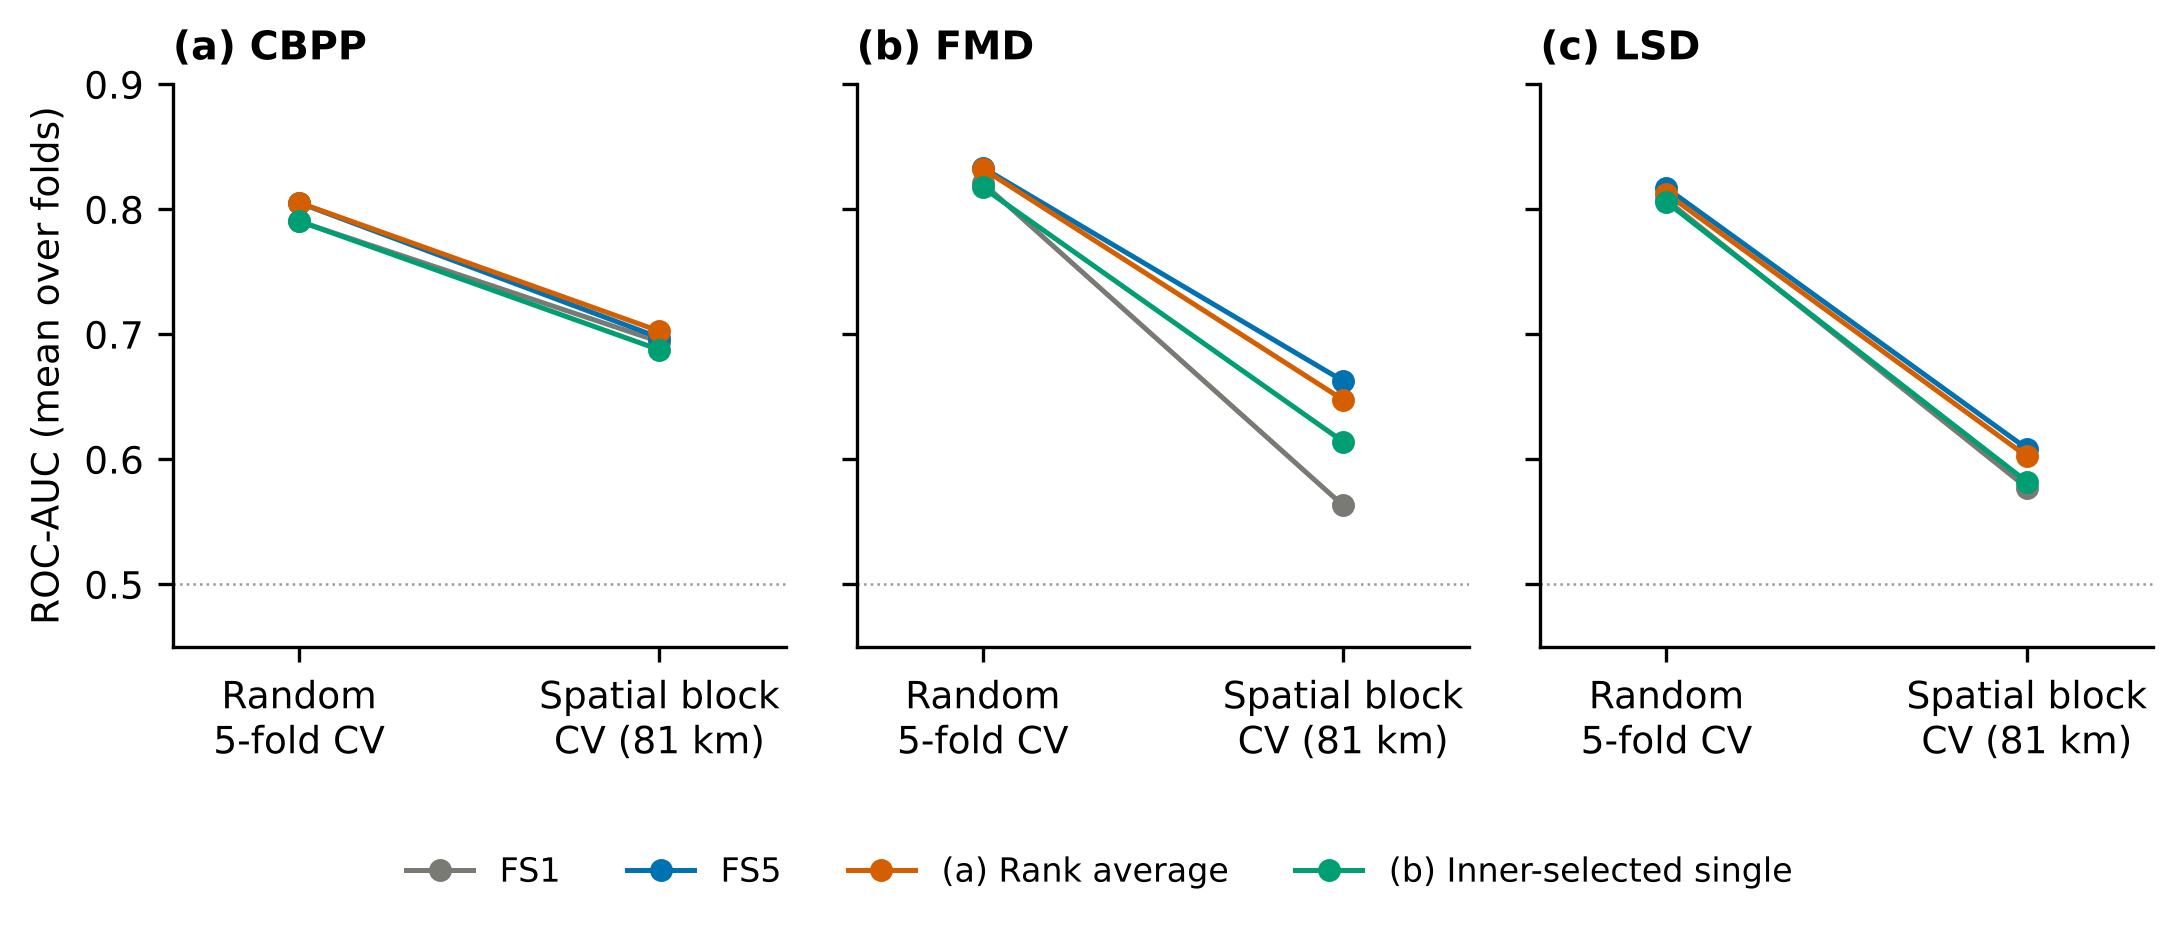

In [11]:
from paper1 import rev_analysis_v1 as RA
T = RA.table_random_vs_spatial(); RA.fig_random_vs_spatial(T); display(RA.TABLES['Random vs spatial CV']); show('Fig3_random_vs_spatial_cv_v1')

## 12. Spatial block cross-validation
Main results (81 km blocks, 15 development splits), and the sensitivity of the FS5 gain to proximity buffers and to 120/160 km blocks. The sensitivity analyses are exploratory.

,Disease,Model,ROC-AUC fold mean (SD),ROC-AUC pooled [95% CI],PR-AUC (no-skill),Brier,Cal. intercept (median),Cal. slope (median),Platt fallback folds,Sensitivity,Specificity,Balanced acc.,F1,MCC
0,CBPP,FS1,0.694 (0.055),"0.711 [0.673, 0.743]",0.401 (0.225),0.157,0.06,1.12,0/15,0.60,0.70,0.65,0.45,0.26
1,CBPP,FS5,0.697 (0.065),"0.712 [0.671, 0.747]",0.409 (0.225),0.156,0.04,0.98,0/15,0.60,0.72,0.66,0.46,0.29
2,CBPP,(a) Rank average,0.703 (0.066),"0.725 [0.685, 0.761]",0.419 (0.225),0.155,0.07,0.94,0/15,0.65,0.69,0.67,0.47,0.30
3,CBPP,(b) Inner-selected single,0.688 (0.055),"0.710 [0.671, 0.746]",0.397 (0.225),0.158,-0.02,0.79,0/15,0.63,0.66,0.64,0.45,0.25
4,FMD,FS1,0.563 (0.101),"0.572 [0.518, 0.625]",0.243 (0.183),0.151,0.01,1.70,3/15,0.42,0.59,0.50,0.19,0.01
5,FMD,FS5,0.663 (0.084),"0.665 [0.615, 0.714]",0.329 (0.183),0.142,0.02,1.17,0/15,0.66,0.58,0.62,0.37,0.19
6,FMD,(a) Rank average,0.648 (0.107),"0.646 [0.585, 0.708]",0.316 (0.183),0.147,-0.01,1.84,0/15,0.56,0.62,0.59,0.34,0.16
7,FMD,(b) Inner-selected single,0.614 (0.108),"0.615 [0.557, 0.671]",0.293 (0.183),0.147,-0.08,1.54,0/15,0.57,0.58,0.57,0.32,0.12
8,LSD,FS1,0.577 (0.070),"0.572 [0.528, 0.607]",0.270 (0.224),0.175,-0.14,1.31,4/15,0.49,0.57,0.53,0.25,0.06
9,LSD,FS5,0.609 (0.090),"0.600 [0.554, 0.641]",0.302 (0.224),0.177,-0.12,1.24,0/15,0.54,0.57,0.56,0.33,0.10


,Condition,Disease,Training households,Training locations,Removed households,Min test positives,Median nearest training location (km),FS1 ROC-AUC,FS5 ROC-AUC,FS5 - FS1 [95% CI],Folds > 0,FS1 PR-AUC,FS5 PR-AUC,No-skill PR-AUC
0,base81,CBPP,2672,370,0,78,38,0.694,0.697,"+0.003 [-0.034, +0.041]",8/15,0.401,0.409,0.225
1,buffer_25,CBPP,2400,331,272,78,56,0.683,0.689,"+0.006 [-0.049, +0.060]",10/15,0.388,0.389,0.225
2,matched_25,CBPP,2391,331,281,78,38,0.692,0.697,"+0.005 [-0.036, +0.045]",10/15,0.398,0.408,0.225
3,buffer_50,CBPP,2062,284,610,78,72,0.672,0.667,"-0.005 [-0.064, +0.055]",8/15,0.373,0.377,0.225
4,matched_50,CBPP,2058,287,614,78,38,0.694,0.694,"+0.000 [-0.041, +0.041]",8/15,0.404,0.405,0.225
5,buffer_100,CBPP,1107,153,1565,78,126,0.620,0.634,"+0.014 [-0.112, +0.141]",11/15,0.327,0.351,0.225
6,matched_100,CBPP,1625,226,1047,78,38,0.694,0.697,"+0.003 [-0.035, +0.041]",6/15,0.397,0.413,0.225
7,base81,FMD,2672,370,0,79,38,0.563,0.663,"+0.100 [+0.025, +0.175]",14/15,0.243,0.329,0.183
8,buffer_25,FMD,2400,331,272,79,56,0.504,0.625,"+0.121 [+0.067, +0.176]",15/15,0.196,0.295,0.183
9,matched_25,FMD,2391,331,281,79,38,0.576,0.657,"+0.081 [+0.014, +0.147]",14/15,0.253,0.316,0.183


,Condition,Disease,Training households,Training locations,Removed households,Min test positives,Median nearest training location (km),FS1 ROC-AUC,FS5 ROC-AUC,FS5 - FS1 [95% CI],Folds > 0,FS1 PR-AUC,FS5 PR-AUC,No-skill PR-AUC
0,base81,CBPP,2672,370,0,78,38,0.694,0.697,"+0.003 [-0.034, +0.041]",8/15,0.401,0.409,0.225
1,blocks120,CBPP,2672,370,0,76,49,0.661,0.665,"+0.004 [-0.030, +0.038]",9/15,0.383,0.390,0.225
2,blocks160,CBPP,2672,370,0,53,61,0.654,0.665,"+0.012 [-0.028, +0.051]",6/15,0.345,0.355,0.221
3,base81,FMD,2672,370,0,79,38,0.563,0.663,"+0.100 [+0.025, +0.175]",14/15,0.243,0.329,0.183
4,blocks120,FMD,2672,370,0,42,49,0.504,0.626,"+0.122 [-0.026, +0.271]",12/15,0.204,0.305,0.182
5,blocks160,FMD,2672,370,0,42,61,0.526,0.627,"+0.101 [+0.010, +0.191]",15/15,0.206,0.282,0.180
6,base81,LSD,2672,370,0,116,38,0.577,0.609,"+0.031 [-0.039, +0.102]",9/15,0.270,0.302,0.224
7,blocks120,LSD,2672,370,0,98,49,0.559,0.587,"+0.029 [-0.058, +0.115]",10/15,0.257,0.299,0.223
8,blocks160,LSD,2672,370,0,66,61,0.558,0.591,"+0.033 [-0.052, +0.119]",11/15,0.257,0.287,0.223


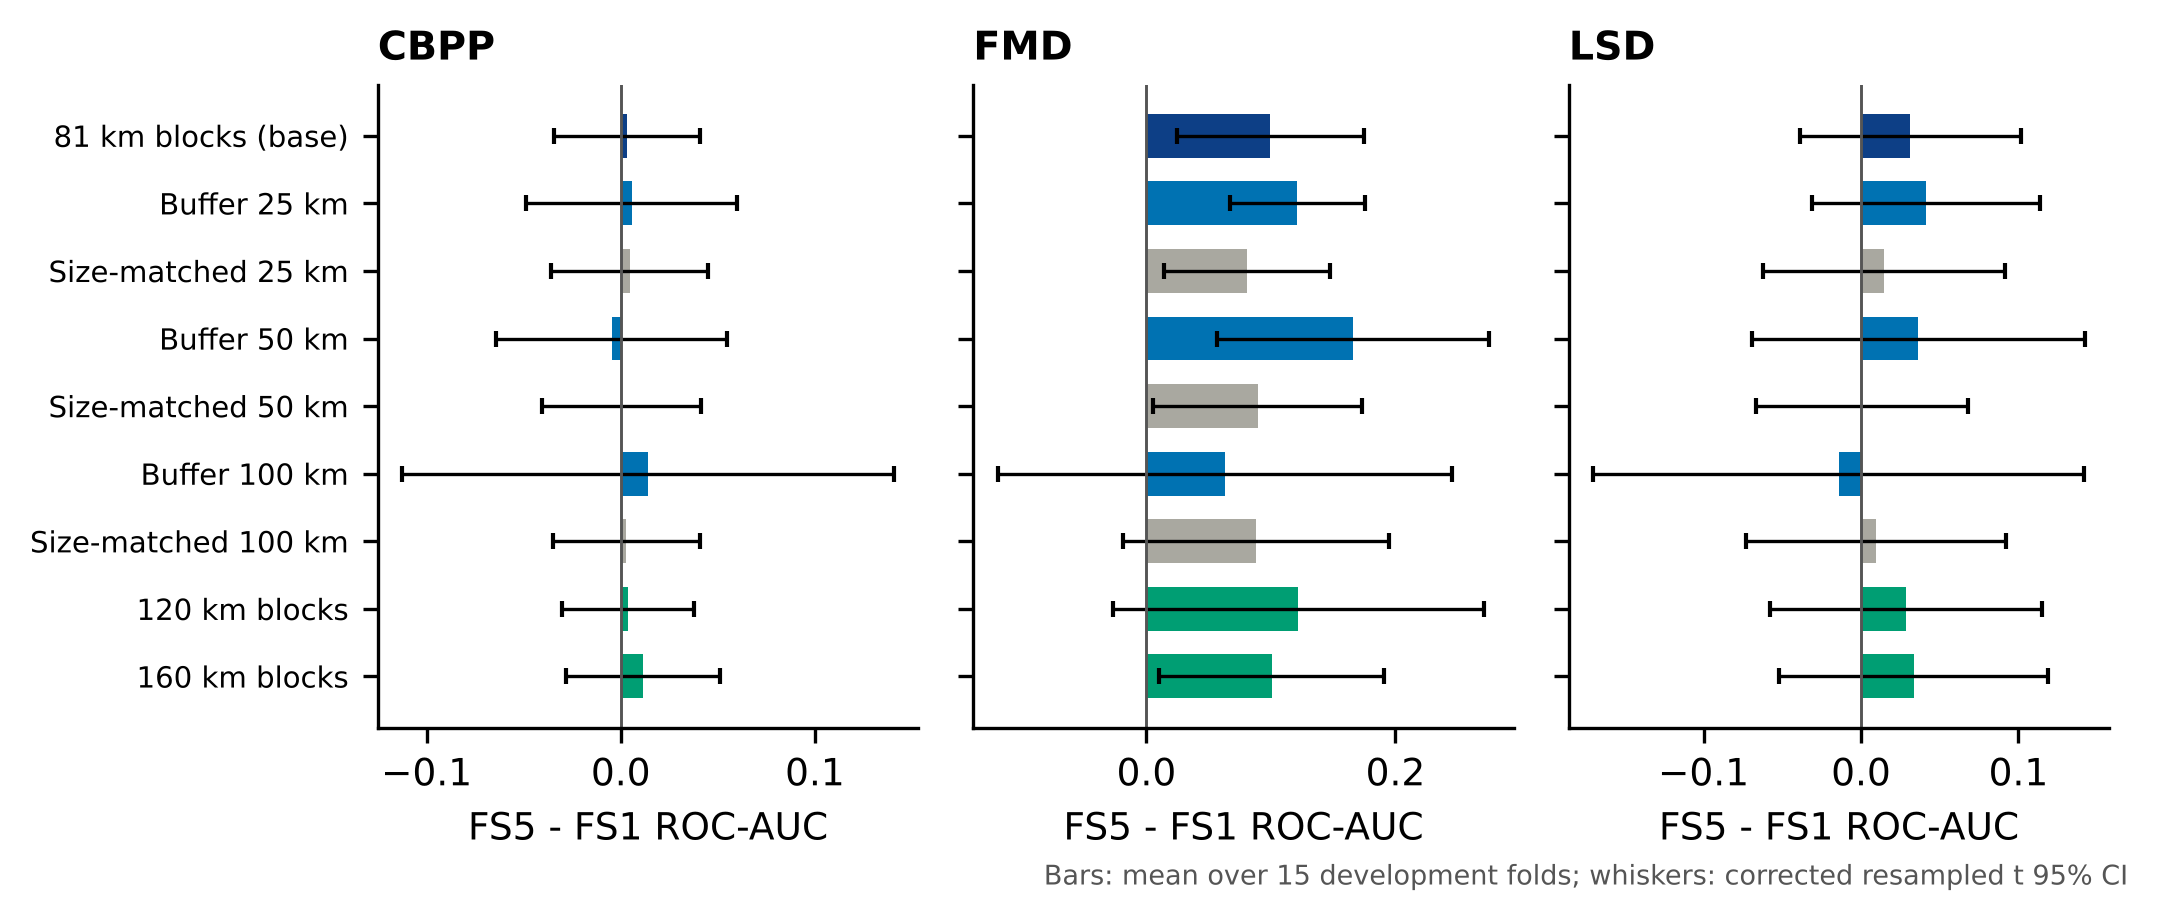

In [12]:
display(tab(P1 / 'tables/Table4_overall_spatial_performance_v1.csv')); display(tab(P1 / 'tables/Table9_proximity_removal_v1.csv')); display(tab(P1 / 'tables/Table8_block_size_sensitivity_v1.csv'))
show('Fig4_spatial_sensitivity_v2')

## 13. Feature ablation experiments
FS1 -> FS5 on identical folds, inner folds and seeds. Each step adds one feature group; differences are tested with the corrected resampled t-test (Holm over 12 tests) and a location-cluster bootstrap of pooled predictions.

,Disease,Feature set,Features,ROC-AUC fold mean (SD),ROC-AUC pooled [95% CI],PR-AUC fold mean (no-skill),Within-year AUC fold mean
0,CBPP,FS1,5,0.694 (0.055),"0.711 [0.673, 0.743]",0.401 (0.224),0.576
1,CBPP,FS2,11,0.687 (0.061),"0.704 [0.666, 0.738]",0.400 (0.224),0.579
2,CBPP,FS3,15,0.697 (0.064),"0.715 [0.676, 0.751]",0.411 (0.224),0.576
3,CBPP,FS4,33,0.700 (0.067),"0.716 [0.674, 0.753]",0.407 (0.224),0.567
4,CBPP,FS5,39,0.697 (0.065),"0.712 [0.671, 0.747]",0.409 (0.224),0.563
5,FMD,FS1,5,0.563 (0.101),"0.572 [0.518, 0.625]",0.243 (0.183),0.527
6,FMD,FS2,11,0.603 (0.095),"0.612 [0.562, 0.662]",0.280 (0.183),0.548
7,FMD,FS3,15,0.638 (0.113),"0.651 [0.600, 0.704]",0.316 (0.183),0.564
8,FMD,FS4,33,0.646 (0.090),"0.657 [0.605, 0.708]",0.317 (0.183),0.572
9,FMD,FS5,39,0.663 (0.084),"0.665 [0.615, 0.714]",0.329 (0.183),0.586


,Step,Added group,Disease,Fold mean [corrected-t 95% CI],Folds > 0,p,Pooled [bootstrap 95% CI],Within-year fold mean [corrected-t 95% CI],Holm p (12 tests)
0,FS2 - FS1,Climate indices (6),CBPP,"-0.007 [-0.036, +0.023]",6/15,0.631,"-0.007 [-0.016, +0.002]","+0.003 [-0.024, +0.029]",1.000
1,FS3 - FS2,Coordinates (4),CBPP,"+0.010 [-0.007, +0.026]",10/15,0.235,"+0.010 [-0.005, +0.025]","-0.003 [-0.046, +0.040]",1.000
2,FS4 - FS3,Neighbourhood and cross-disease rates (18),CBPP,"+0.003 [-0.031, +0.037]",8/15,0.858,"+0.001 [-0.010, +0.012]","-0.009 [-0.050, +0.032]",1.000
3,FS5 - FS4,Sampling density (6),CBPP,"-0.003 [-0.021, +0.016]",6/15,0.773,"-0.004 [-0.010, +0.001]","-0.004 [-0.031, +0.023]",1.000
4,FS2 - FS1,Climate indices (6),FMD,"+0.040 [-0.015, +0.095]",12/15,0.144,"+0.040 [+0.019, +0.062]","+0.021 [-0.017, +0.059]",1.000
5,FS3 - FS2,Coordinates (4),FMD,"+0.035 [-0.017, +0.087]",12/15,0.171,"+0.039 [+0.017, +0.063]","+0.016 [-0.052, +0.085]",1.000
6,FS4 - FS3,Neighbourhood and cross-disease rates (18),FMD,"+0.008 [-0.051, +0.067]",8/15,0.776,"+0.006 [-0.009, +0.020]","+0.008 [-0.084, +0.100]",1.000
7,FS5 - FS4,Sampling density (6),FMD,"+0.017 [-0.012, +0.045]",13/15,0.222,"+0.008 [-0.000, +0.017]","+0.014 [-0.039, +0.068]",1.000
8,FS2 - FS1,Climate indices (6),LSD,"+0.012 [-0.023, +0.047]",9/15,0.485,"+0.011 [-0.012, +0.032]","-0.005 [-0.086, +0.075]",1.000
9,FS3 - FS2,Coordinates (4),LSD,"+0.011 [-0.022, +0.044]",10/15,0.477,"+0.015 [+0.001, +0.029]","+0.009 [-0.033, +0.050]",1.000


saved R2Fig1_ablation_v3


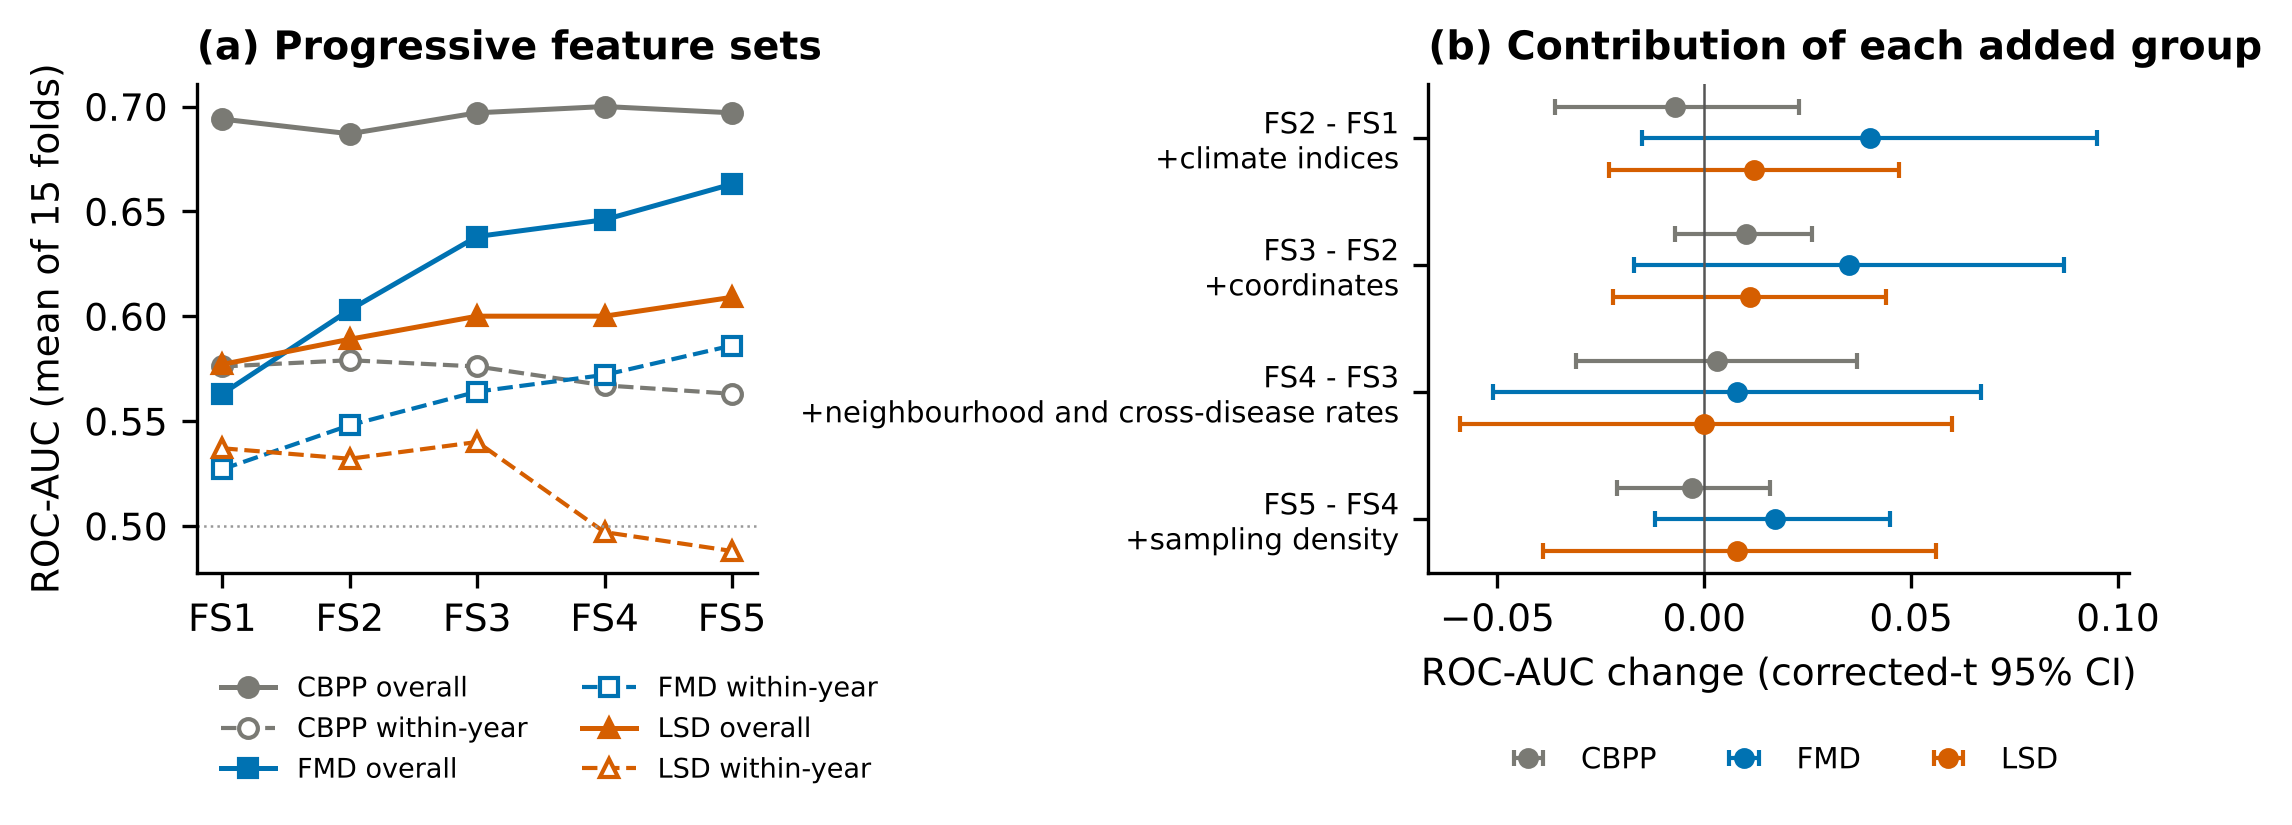

In [13]:
from paper1 import rev2_analysis_v1 as RV
TA, IA = RV.ablation(); display(TA.drop(columns=[c for c in TA if c.startswith('_')])); display(IA.drop(columns=[c for c in IA if c.startswith('_')]))
runpy.run_path('src/paper1/rev2_figures_v3.py', run_name='__main__'); show('R2Fig1_ablation_v3')

## 14. Model comparison
All 23 library models, the rank-average ensemble (a), the inner-selected single model (b), and the ensemble without the group-balanced CatBoost model.

In [14]:
display(RA.table_library()); display(tab(P1 / 'tables/Table7_disease_specific_comparisons_v1.csv')); display(RV.ensemble_without_gb())
display(tab(P1 / 'tables/Table11_ensemble_prior_sensitivity_v1.csv'))   # effect of the two code corrections on the rank average

Saving to: /home/claude/fresh/proj/_paper1_scratch_v1
{'python': '3.13.18', 'numpy': '2.5.3', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'catboost': '1.2.10'}
Full run


3340 households, 462 locations; folds loaded from run 1
26 splits: {'spatial': 15, 'loro': 6, 'random': 5}
Feature sets: B = 5  E = 14  EL = 26  ELK = 36


,Model [feature set],CBPP ROC-AUC mean (SD),FMD ROC-AUC mean (SD),LSD ROC-AUC mean (SD)
9,GAM [B],0.703 (0.046),0.547 (0.070),0.565 (0.055)
17,RF [B],0.678 (0.068),0.571 (0.098),0.583 (0.068)
20,XGB [B],0.662 (0.081),0.551 (0.108),0.564 (0.063)
0,CatBoost [B],0.664 (0.081),0.555 (0.112),0.574 (0.083)
2,CatBoost [E],0.677 (0.078),0.616 (0.115),0.594 (0.098)
22,kNN [E],0.678 (0.061),0.609 (0.094),0.560 (0.086)
14,LR [EL],0.674 (0.049),0.652 (0.088),0.558 (0.059)
10,GAM [EL],0.694 (0.062),0.624 (0.117),0.574 (0.076)
18,RF [EL],0.698 (0.070),0.634 (0.101),0.587 (0.091)
8,ExtraTrees [EL],0.698 (0.065),0.655 (0.097),0.597 (0.094)


,Comparison,Disease,Overall: fold mean [corrected-t 95% CI],Overall: folds > 0,Overall: pooled [bootstrap 95% CI],Within-year: fold mean [corrected-t 95% CI],Within-year: folds > 0,Within-year: pooled [bootstrap 95% CI],Overall: Holm p,Within-year: Holm p
0,FS5 minus FS1,CBPP,"+0.003 [-0.034, +0.041]",8/15,"+0.001 [-0.022, +0.022]","-0.013 [-0.074, +0.047]",5/15,"-0.004 [-0.028, +0.021]",0.858,0.733
1,FS5 minus FS1,FMD,"+0.100 [+0.025, +0.175]",14/15,"+0.093 [+0.057, +0.126]","+0.060 [-0.046, +0.165]",11/15,"+0.066 [+0.011, +0.117]",0.039,0.732
2,FS5 minus FS1,LSD,"+0.031 [-0.039, +0.102]",9/15,"+0.028 [-0.007, +0.066]","-0.049 [-0.161, +0.063]",4/15,"-0.049 [-0.115, +0.007]",0.711,0.733
3,(a) Rank average minus FS5,CBPP,"+0.005 [-0.023, +0.033]",8/15,"+0.013 [+0.003, +0.024]","+0.011 [-0.025, +0.047]",8/15,"+0.012 [-0.001, +0.026]",1.000,1.000
4,(a) Rank average minus FS5,FMD,"-0.015 [-0.061, +0.031]",4/15,"-0.019 [-0.037, -0.002]","-0.004 [-0.057, +0.049]",8/15,"-0.004 [-0.025, +0.015]",1.000,1.000
5,(a) Rank average minus FS5,LSD,"-0.006 [-0.058, +0.046]",7/15,"+0.000 [-0.023, +0.023]","+0.023 [-0.033, +0.080]",11/15,"+0.026 [+0.007, +0.046]",1.000,1.000


,Disease,"Rank average, 23 models",Without group-balanced CatBoost (22),Difference [corrected-t 95% CI],Max fold |difference|,Within-year difference [corrected-t 95% CI]
0,CBPP,0.703,0.704,"+0.001 [-0.001, +0.002]",0.0043,"+0.001 [-0.002, +0.004]"
1,FMD,0.648,0.646,"-0.001 [-0.004, +0.001]",0.0058,"-0.002 [-0.010, +0.007]"
2,LSD,0.602,0.604,"+0.001 [-0.001, +0.003]",0.0050,"+0.001 [-0.005, +0.006]"


,Disease,Version,Rank-average ROC-AUC (original),Rank-average ROC-AUC (version),Difference [corrected-t 95% CI],Max fold |difference|
0,CBPP,corrected prior,0.702,0.703,"+0.0007 [-0.0029, +0.0043]",0.009
1,CBPP,corrected prior + deterministic ties,0.702,0.703,"+0.0006 [-0.0029, +0.0041]",0.009
2,FMD,corrected prior,0.647,0.648,"+0.0004 [-0.0039, +0.0048]",0.007
3,FMD,corrected prior + deterministic ties,0.647,0.648,"+0.0002 [-0.0036, +0.0040]",0.006
4,LSD,corrected prior,0.604,0.601,"-0.0027 [-0.0067, +0.0012]",0.008
5,LSD,corrected prior + deterministic ties,0.604,0.603,"-0.0016 [-0.0059, +0.0027]",0.007


## 15. Explainability
Grouped permutation importance (15 folds) and SHAP values with partial dependence (FS5 ExtraTrees, repeat 1). Models are fitted on training rows only; SHAP is computed for test rows, partial dependence on training rows. These are predictive associations, not causal effects.

,disease,group,mean_AUC_drop,sd_over_folds,folds
0,CBPP,Climate indices (6),7.139e-03,0.012,15
1,CBPP,Coordinates (4),-4.987e-04,0.008,15
2,CBPP,Cross-disease rates (12),7.667e-04,0.016,15
3,CBPP,Environmental (5),1.660e-02,0.019,15
4,CBPP,Own-disease rates (6),3.541e-02,0.035,15
5,CBPP,Sampling density (6),-3.530e-03,0.011,15
6,FMD,Climate indices (6),2.580e-05,0.019,15
7,FMD,Coordinates (4),1.725e-02,0.023,15
8,FMD,Cross-disease rates (12),2.804e-02,0.030,15
9,FMD,Environmental (5),-4.471e-03,0.016,15


,disease,group,features,mean_abs_SHAP_sum,permutation_AUC_drop
0,CBPP,Environmental,5,0.022,1.660e-02
1,CBPP,Climate indices,6,0.022,7.100e-03
2,CBPP,Coordinates,4,0.008,-5.000e-04
3,CBPP,Own-disease rates,6,0.059,3.540e-02
4,CBPP,Cross-disease rates,12,0.021,8.000e-04
5,CBPP,Sampling density,6,0.016,-3.500e-03
6,FMD,Environmental,5,0.006,-4.500e-03
7,FMD,Climate indices,6,0.009,0.000e+00
8,FMD,Coordinates,4,0.021,1.730e-02
9,FMD,Own-disease rates,6,0.026,3.050e-02


Spearman rho, SHAP vs permutation group ranking: {'CBPP': np.float64(0.94), 'FMD': np.float64(0.94), 'LSD': np.float64(0.83)}


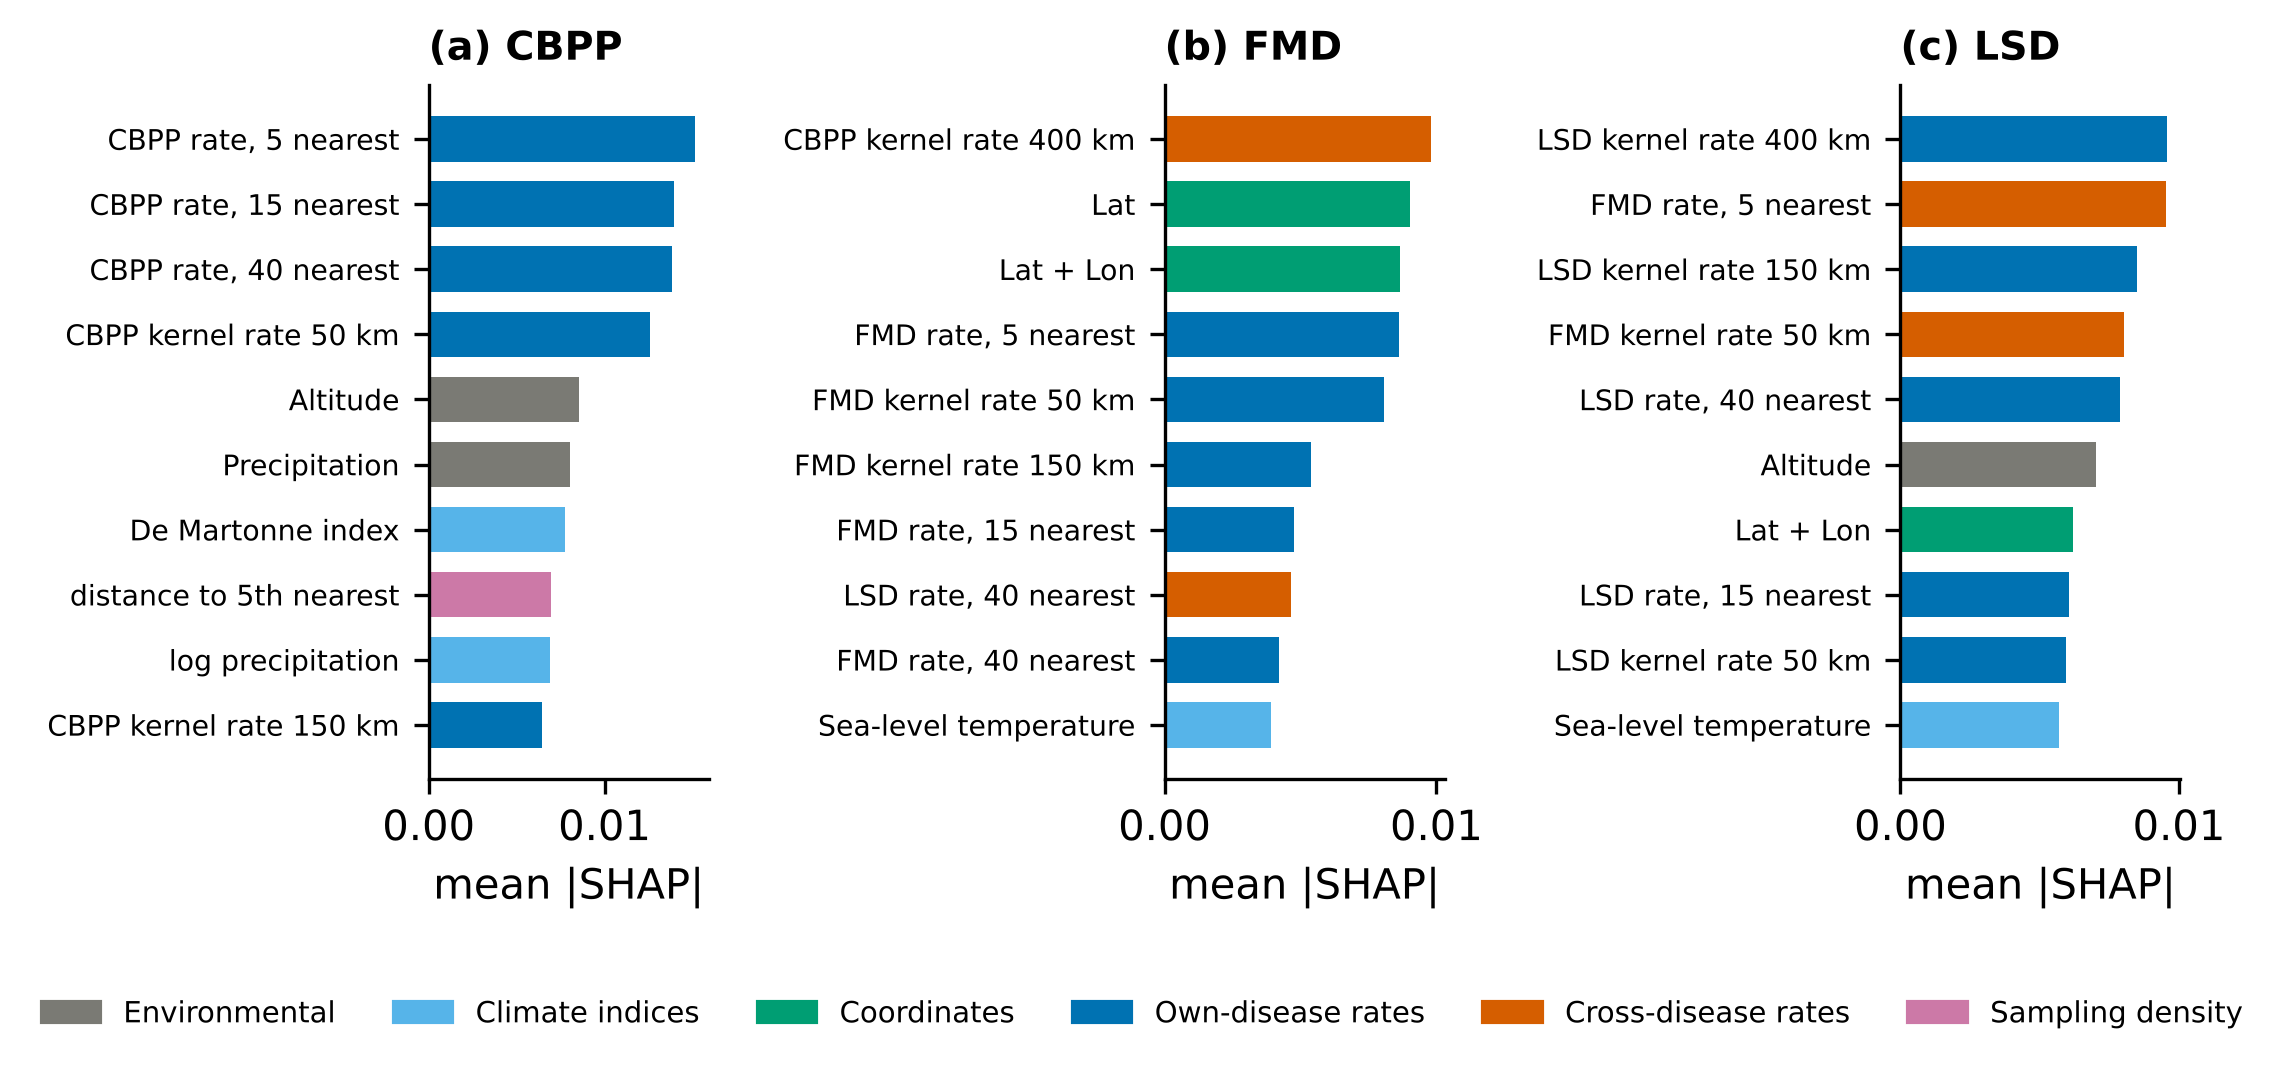

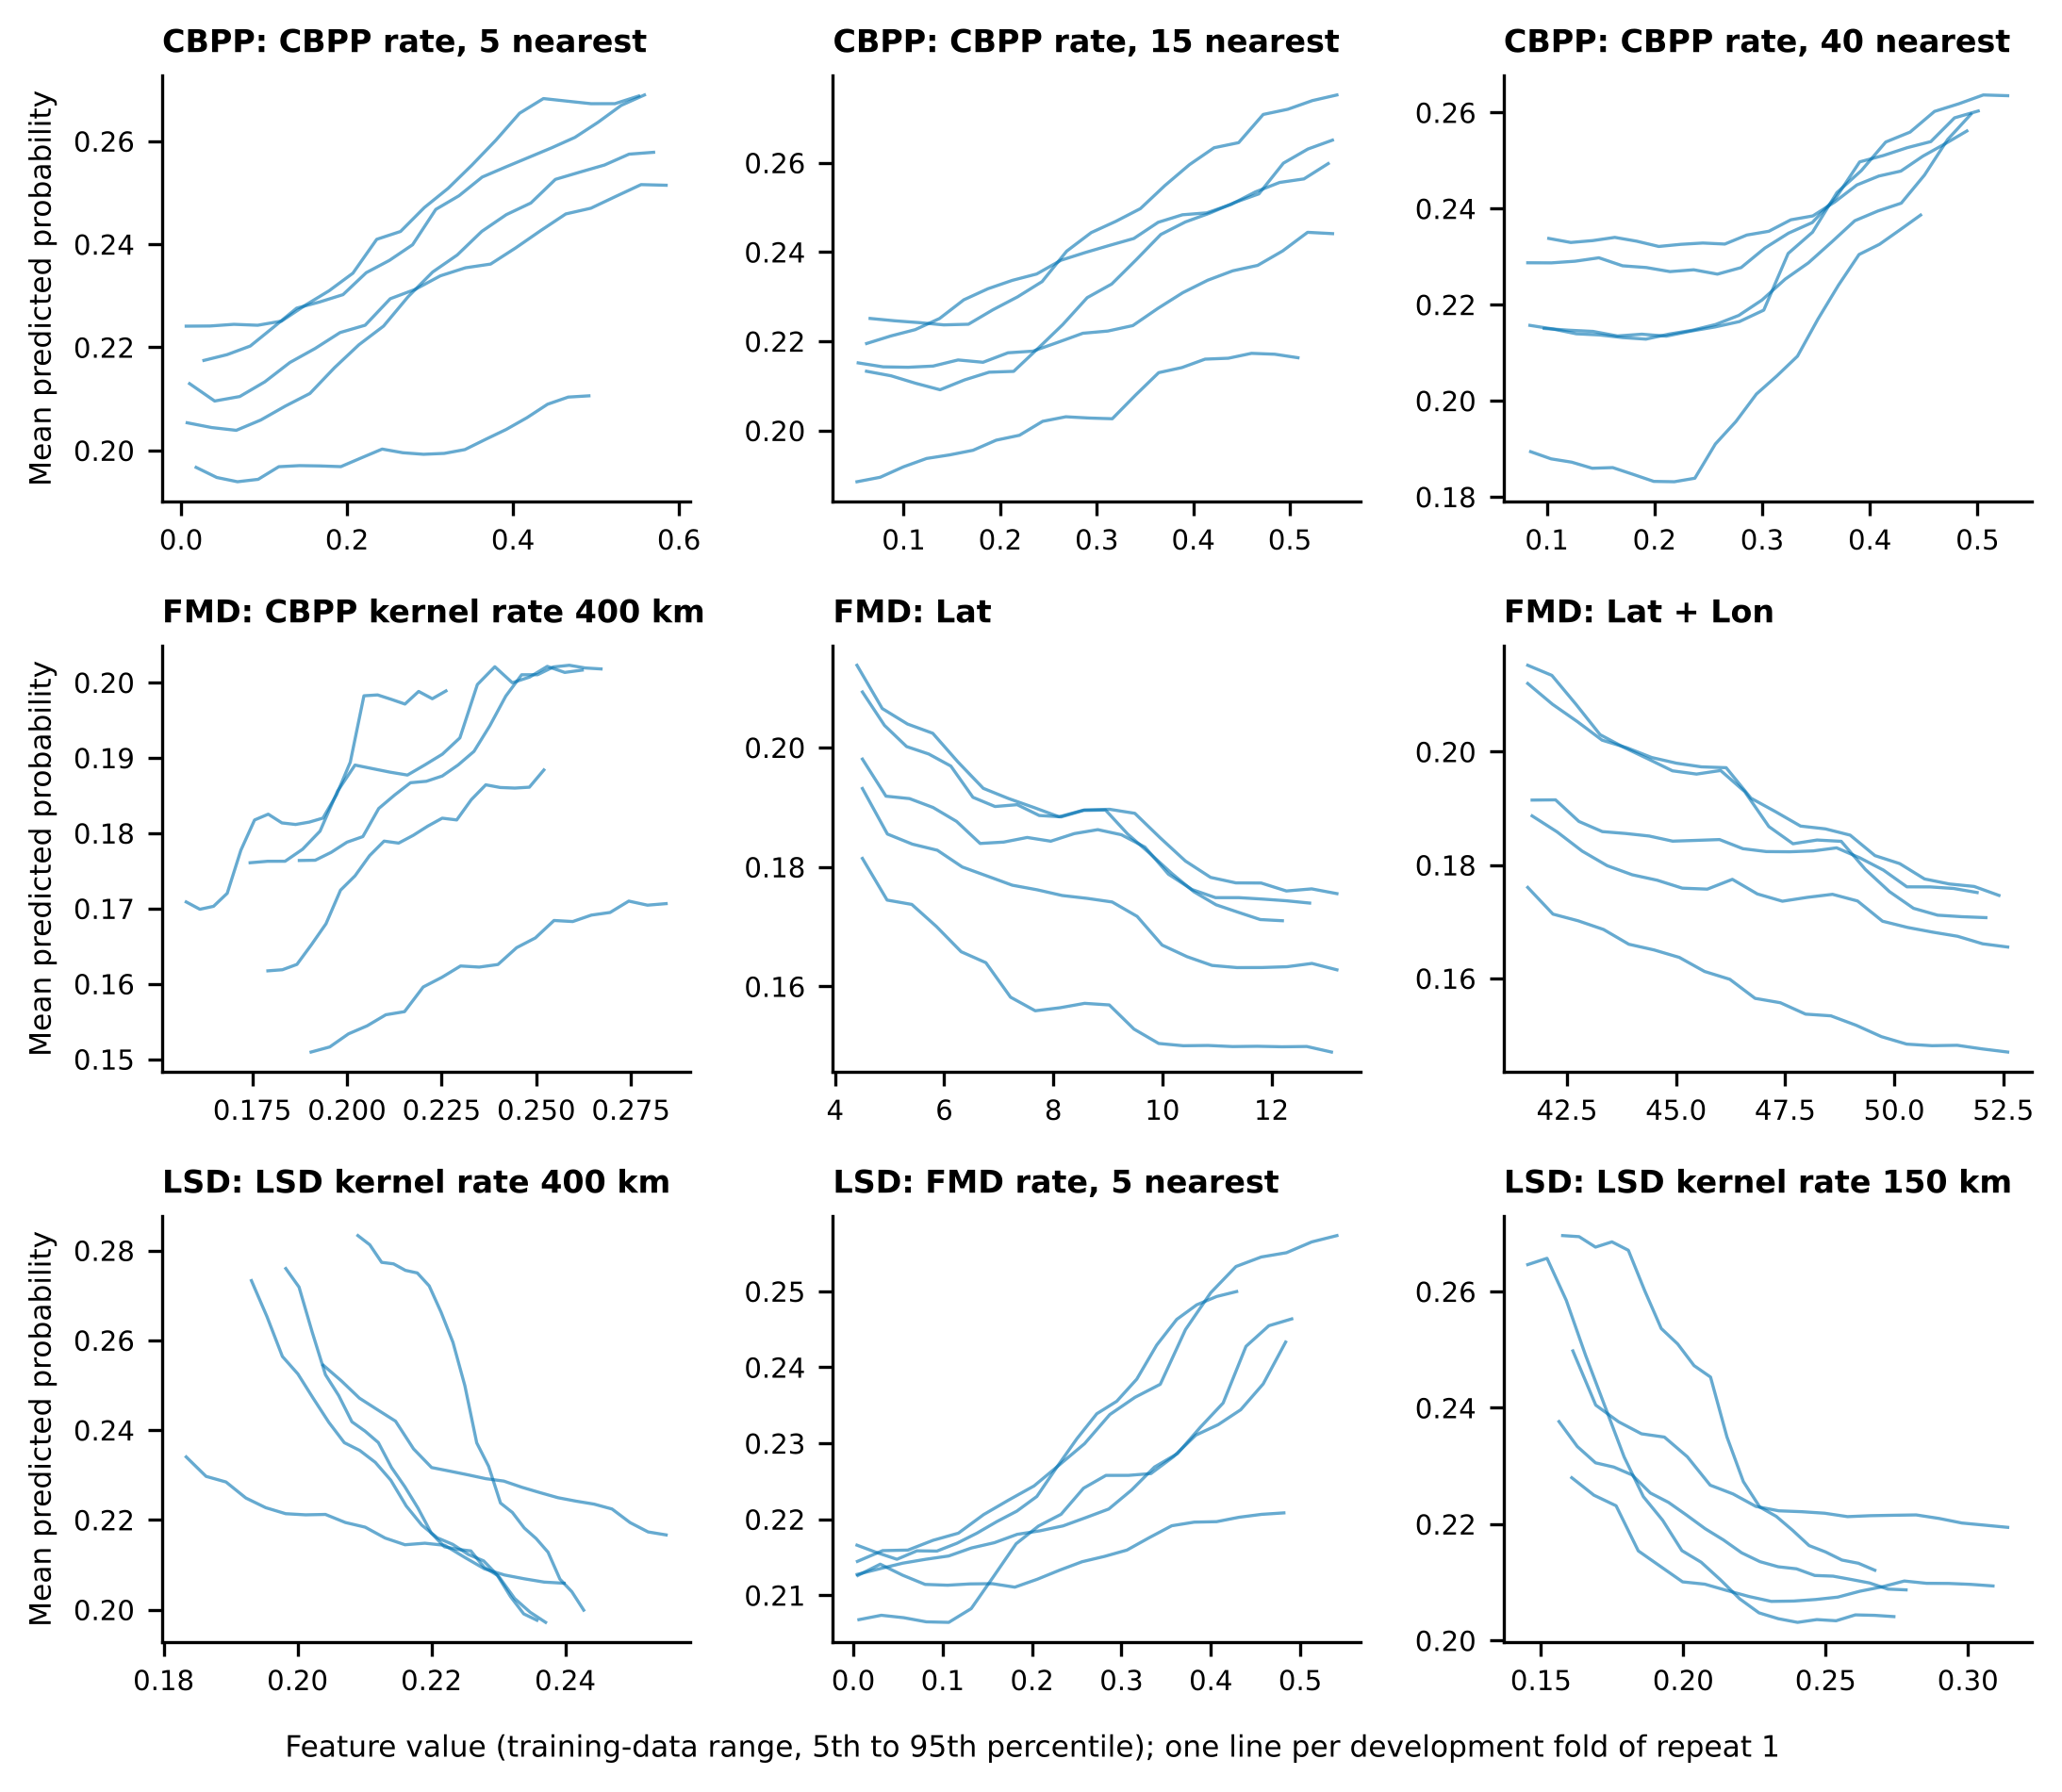

In [15]:
display(tab(P1 / 'tables/TableS_grouped_permutation_importance_v1.csv'))
S, G, rho = RV.shap_pdp(); display(G.round(4)); print('Spearman rho, SHAP vs permutation group ranking:', {k: round(v, 2) for k, v in rho.items()})
show('R2Fig2_shap_top_features_v1'); show('R2Fig3_partial_dependence_v1')

## 16. Spatial applicability
Area of applicability (Meyer and Pebesma 2021) for test locations under spatial CV: importance-weighted standardised distance to the nearest training household, divided by the mean training distance; the threshold comes from inner spatial folds. Environmental values exist only at surveyed locations, so the maps show surveyed locations, not a continuous surface. The dissimilarity index is not a risk or certainty measure.

,Features,Disease,Test households inside AOA (%),Locations ever outside AOA,Median DI,Median threshold,ROC-AUC inside AOA,ROC-AUC outside AOA,Households outside (positives),Spearman DI vs |error|
0,FS1,CBPP,99.5,14,0.131,0.353,0.711,0.643,15 (3),-0.063
1,FS1,FMD,99.3,17,0.136,0.350,0.572,0.792,25 (6),-0.076
2,FS1,LSD,99.4,14,0.137,0.353,0.571,0.828,20 (7),-0.007
3,FS5,CBPP,99.4,10,0.295,0.586,0.711,0.885,19 (5),+0.165
4,FS5,FMD,98.6,20,0.311,0.649,0.666,0.916,47 (3),+0.001
5,FS5,LSD,98.8,13,0.317,0.663,0.605,0.167,39 (4),+0.094


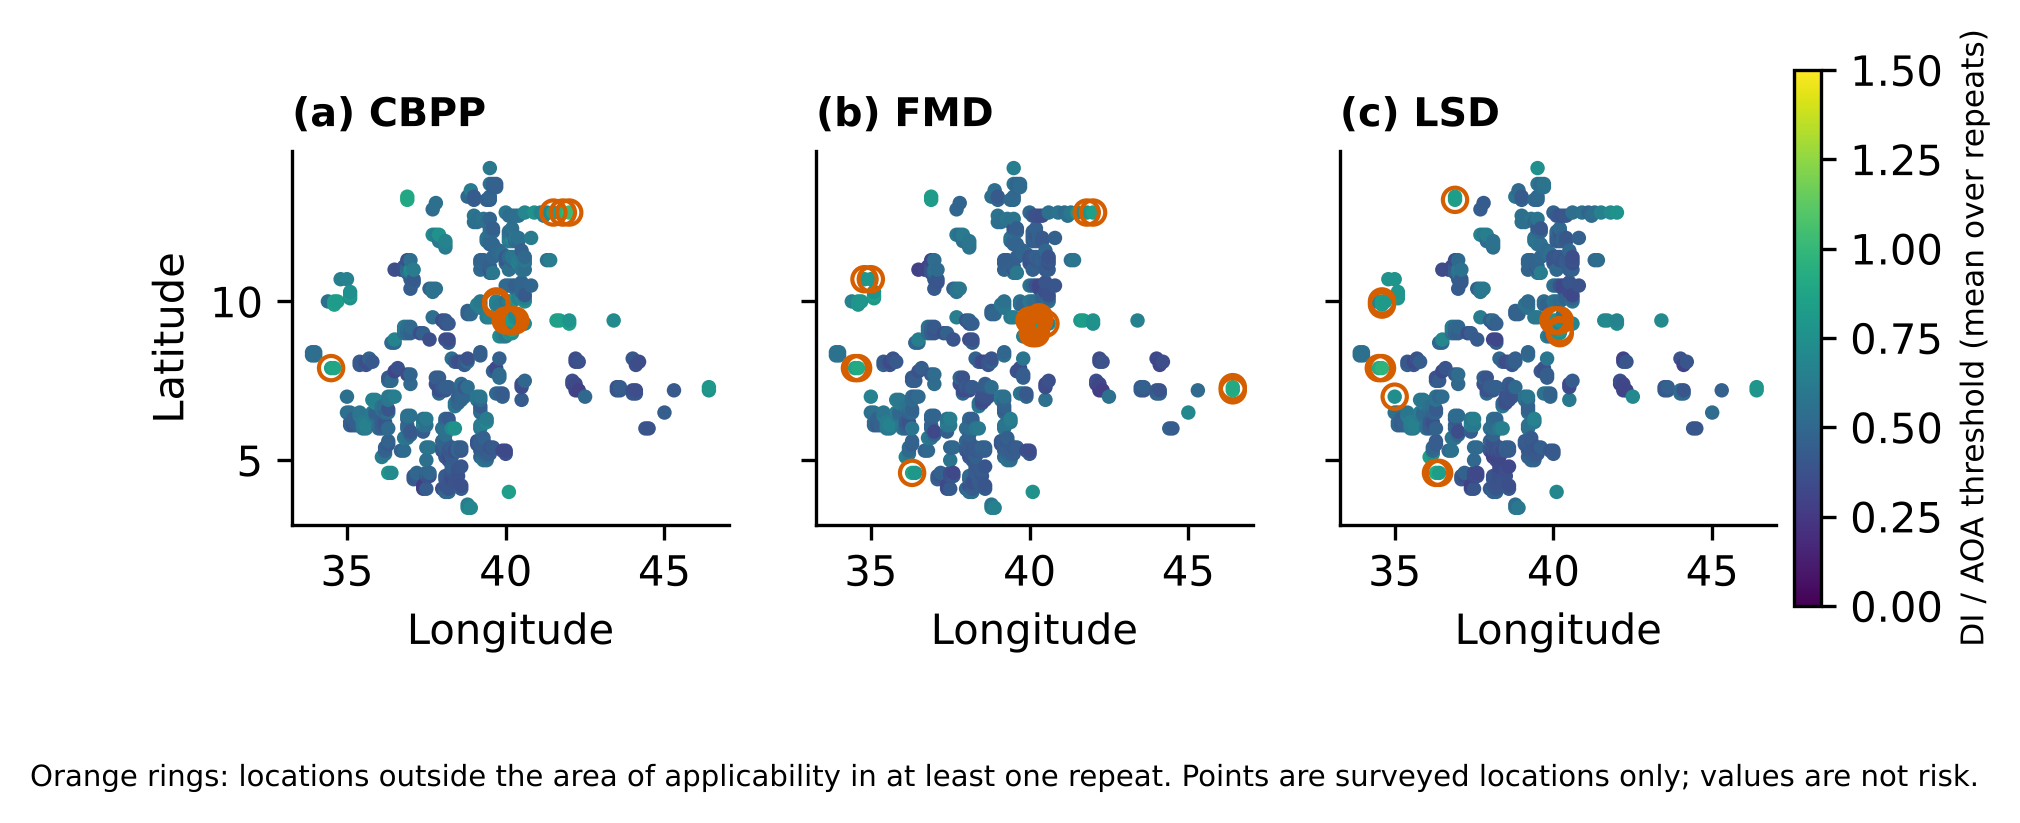

In [16]:
display(RV.aoa()); show('R2Fig4_area_of_applicability_FS5_v1')

## 17. Calibration
Discrimination and calibration are reported separately. Pooled predictions per repeat; 95% intervals from 1,000 location-cluster bootstrap resamples.

,Disease,Model,Prevalence,PR-AUC,Brier,Calibration intercept,Calibration slope,Sensitivity,Specificity,Balanced accuracy,F1,MCC
0,CBPP,FS1,0.224,"0.413 [0.358, 0.467]","0.157 [0.143, 0.174]","-0.026 [-0.182, 0.124]","1.029 [0.815, 1.240]","0.618 [0.551, 0.679]","0.703 [0.649, 0.748]","0.660 [0.626, 0.692]","0.467 [0.416, 0.510]","0.277 [0.218, 0.331]"
1,CBPP,FS5,0.224,"0.422 [0.371, 0.470]","0.156 [0.140, 0.172]","0.016 [-0.124, 0.164]","0.966 [0.779, 1.156]","0.620 [0.553, 0.684]","0.720 [0.672, 0.764]","0.670 [0.637, 0.700]","0.480 [0.432, 0.525]","0.298 [0.241, 0.350]"
2,CBPP,(a) Rank average,0.224,"0.432 [0.380, 0.484]","0.154 [0.139, 0.170]","0.001 [-0.147, 0.147]","0.958 [0.754, 1.176]","0.665 [0.603, 0.726]","0.689 [0.636, 0.734]","0.677 [0.646, 0.706]","0.485 [0.441, 0.527]","0.303 [0.248, 0.354]"
3,CBPP,(b) Inner-selected single,0.224,"0.415 [0.365, 0.464]","0.157 [0.142, 0.174]","-0.054 [-0.203, 0.093]","0.829 [0.663, 0.998]","0.657 [0.588, 0.718]","0.665 [0.615, 0.715]","0.661 [0.629, 0.694]","0.467 [0.419, 0.512]","0.274 [0.218, 0.332]"
4,FMD,FS1,0.183,"0.244 [0.207, 0.289]","0.150 [0.131, 0.174]","0.012 [-0.200, 0.235]","-0.351 [-1.333, 0.772]","0.409 [0.356, 0.467]","0.600 [0.561, 0.634]","0.504 [0.478, 0.532]","0.253 [0.219, 0.285]","0.006 [-0.035, 0.050]"
5,FMD,FS5,0.183,"0.328 [0.282, 0.378]","0.142 [0.123, 0.164]","-0.010 [-0.202, 0.203]","0.969 [0.627, 1.313]","0.663 [0.581, 0.732]","0.576 [0.523, 0.622]","0.620 [0.583, 0.658]","0.373 [0.330, 0.411]","0.187 [0.132, 0.240]"
6,FMD,(a) Rank average,0.183,"0.316 [0.271, 0.365]","0.146 [0.126, 0.170]","0.013 [-0.196, 0.228]","0.698 [0.172, 1.414]","0.574 [0.482, 0.660]","0.628 [0.585, 0.667]","0.601 [0.560, 0.643]","0.358 [0.312, 0.400]","0.163 [0.100, 0.225]"
7,FMD,(b) Inner-selected single,0.183,"0.284 [0.244, 0.329]","0.147 [0.128, 0.171]","0.024 [-0.187, 0.242]","0.590 [0.120, 1.039]","0.567 [0.476, 0.653]","0.579 [0.535, 0.621]","0.573 [0.530, 0.613]","0.327 [0.285, 0.367]","0.113 [0.048, 0.173]"
8,LSD,FS1,0.224,"0.255 [0.215, 0.300]","0.175 [0.155, 0.196]","0.009 [-0.216, 0.210]","0.224 [-0.469, 0.883]","0.494 [0.426, 0.550]","0.567 [0.523, 0.611]","0.530 [0.499, 0.558]","0.325 [0.277, 0.367]","0.051 [-0.001, 0.098]"
9,LSD,FS5,0.224,"0.277 [0.234, 0.321]","0.176 [0.157, 0.198]","-0.000 [-0.218, 0.206]","0.112 [-0.338, 0.565]","0.523 [0.448, 0.596]","0.572 [0.530, 0.611]","0.548 [0.511, 0.582]","0.346 [0.295, 0.388]","0.080 [0.019, 0.136]"


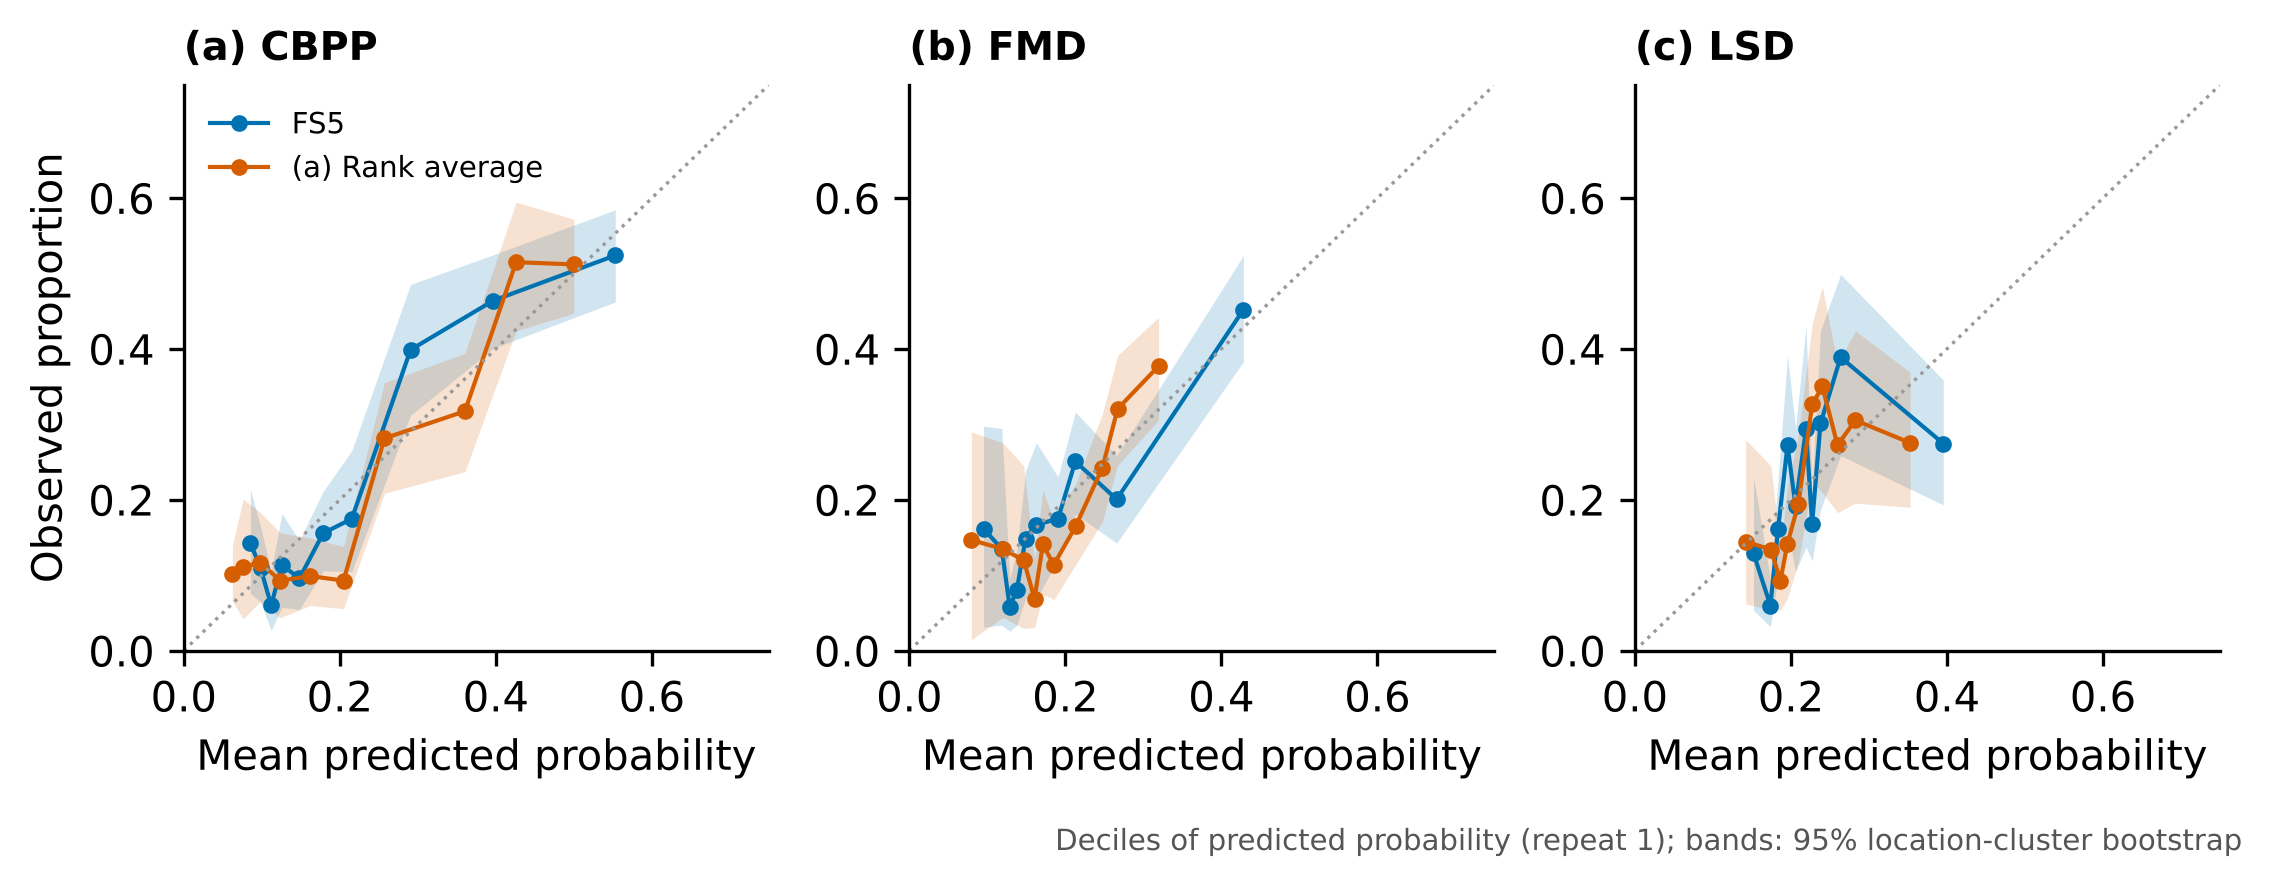

,Disease,Model,Calibration slope: fold median (IQR),Calibration slope: pooled [95% CI],Calibration intercept: fold median,Calibration intercept: pooled [95% CI],Brier: pooled [95% CI],Reference Brier p(1-p),Brier skill score [95% CI],Platt fallbacks (folds)
0,CBPP,FS1,1.12 (0.95 to 1.26),"1.03 [0.81, 1.24]",+0.06,"-0.03 [-0.18, +0.12]","0.157 [0.143, 0.174]",0.174,"+0.097 [-0.001, +0.177]",0
1,CBPP,FS5,0.98 (0.89 to 1.29),"0.97 [0.78, 1.16]",+0.04,"+0.02 [-0.12, +0.16]","0.156 [0.140, 0.172]",0.174,"+0.103 [+0.010, +0.195]",0
2,CBPP,(a) Rank average,0.94 (0.87 to 1.14),"0.96 [0.75, 1.18]",+0.07,"+0.00 [-0.15, +0.15]","0.154 [0.139, 0.170]",0.174,"+0.114 [+0.022, +0.200]",0
3,CBPP,(b) Inner-selected single,0.79 (0.75 to 0.93),"0.83 [0.66, 1.00]",-0.02,"-0.05 [-0.20, +0.09]","0.157 [0.142, 0.174]",0.174,"+0.097 [-0.001, +0.183]",0
4,FMD,FS1,1.70 (0.31 to 2.84),"-0.35 [-1.33, 0.77]",+0.01,"+0.01 [-0.20, +0.23]","0.150 [0.131, 0.174]",0.150,"-0.003 [-0.164, +0.124]",3
5,FMD,FS5,1.17 (1.05 to 1.67),"0.97 [0.63, 1.31]",+0.02,"-0.01 [-0.20, +0.20]","0.142 [0.123, 0.164]",0.150,"+0.050 [-0.097, +0.177]",0
6,FMD,(a) Rank average,1.84 (1.16 to 2.43),"0.70 [0.17, 1.41]",-0.01,"+0.01 [-0.20, +0.23]","0.146 [0.126, 0.170]",0.150,"+0.023 [-0.137, +0.157]",0
7,FMD,(b) Inner-selected single,1.54 (0.26 to 1.74),"0.59 [0.12, 1.04]",-0.08,"+0.02 [-0.19, +0.24]","0.147 [0.128, 0.171]",0.150,"+0.017 [-0.144, +0.144]",0
8,LSD,FS1,1.31 (0.16 to 1.90),"0.22 [-0.47, 0.88]",-0.14,"+0.01 [-0.22, +0.21]","0.175 [0.155, 0.196]",0.174,"-0.007 [-0.128, +0.108]",4
9,LSD,FS5,1.24 (0.29 to 4.35),"0.11 [-0.34, 0.56]",-0.12,"-0.00 [-0.22, +0.21]","0.176 [0.157, 0.198]",0.174,"-0.013 [-0.139, +0.097]",0


In [17]:
display(RV.metric_cis()); show('R2Fig5_calibration_with_bands_v1')
display(R3.calibration_table())   # fold-level medians and pooled estimates side by side, with the Brier skill score

## 18. Survey-campaign analysis
Within-year AUC, year-specific AUC, campaign-specific versus pooled models, and whether the features (especially the neighbourhood rates) identify the survey campaign.

,Disease,Model,ROC-AUC pooled [95% CI],Within-year AUC pooled [95% CI],Within-year AUC fold mean (macro)
0,CBPP,FS1,"0.711 [0.673, 0.743]","0.583 [0.547, 0.618]",0.576 (0.570)
1,CBPP,FS5,"0.712 [0.671, 0.747]","0.580 [0.542, 0.618]",0.563 (0.546)
2,CBPP,(a) Rank average,"0.725 [0.685, 0.761]","0.591 [0.552, 0.631]",0.574 (0.576)
3,CBPP,(b) Inner-selected single,"0.710 [0.671, 0.746]","0.578 [0.542, 0.614]",0.554 (0.535)
4,FMD,FS1,"0.572 [0.518, 0.625]","0.546 [0.510, 0.580]",0.527 (0.561)
5,FMD,FS5,"0.665 [0.615, 0.714]","0.611 [0.562, 0.663]",0.586 (0.555)
6,FMD,(a) Rank average,"0.646 [0.585, 0.708]","0.607 [0.555, 0.661]",0.582 (0.570)
7,FMD,(b) Inner-selected single,"0.615 [0.557, 0.671]","0.560 [0.509, 0.610]",0.546 (0.528)
8,LSD,FS1,"0.572 [0.528, 0.607]","0.554 [0.512, 0.594]",0.537 (0.534)
9,LSD,FS5,"0.600 [0.554, 0.641]","0.505 [0.440, 0.562]",0.488 (0.481)


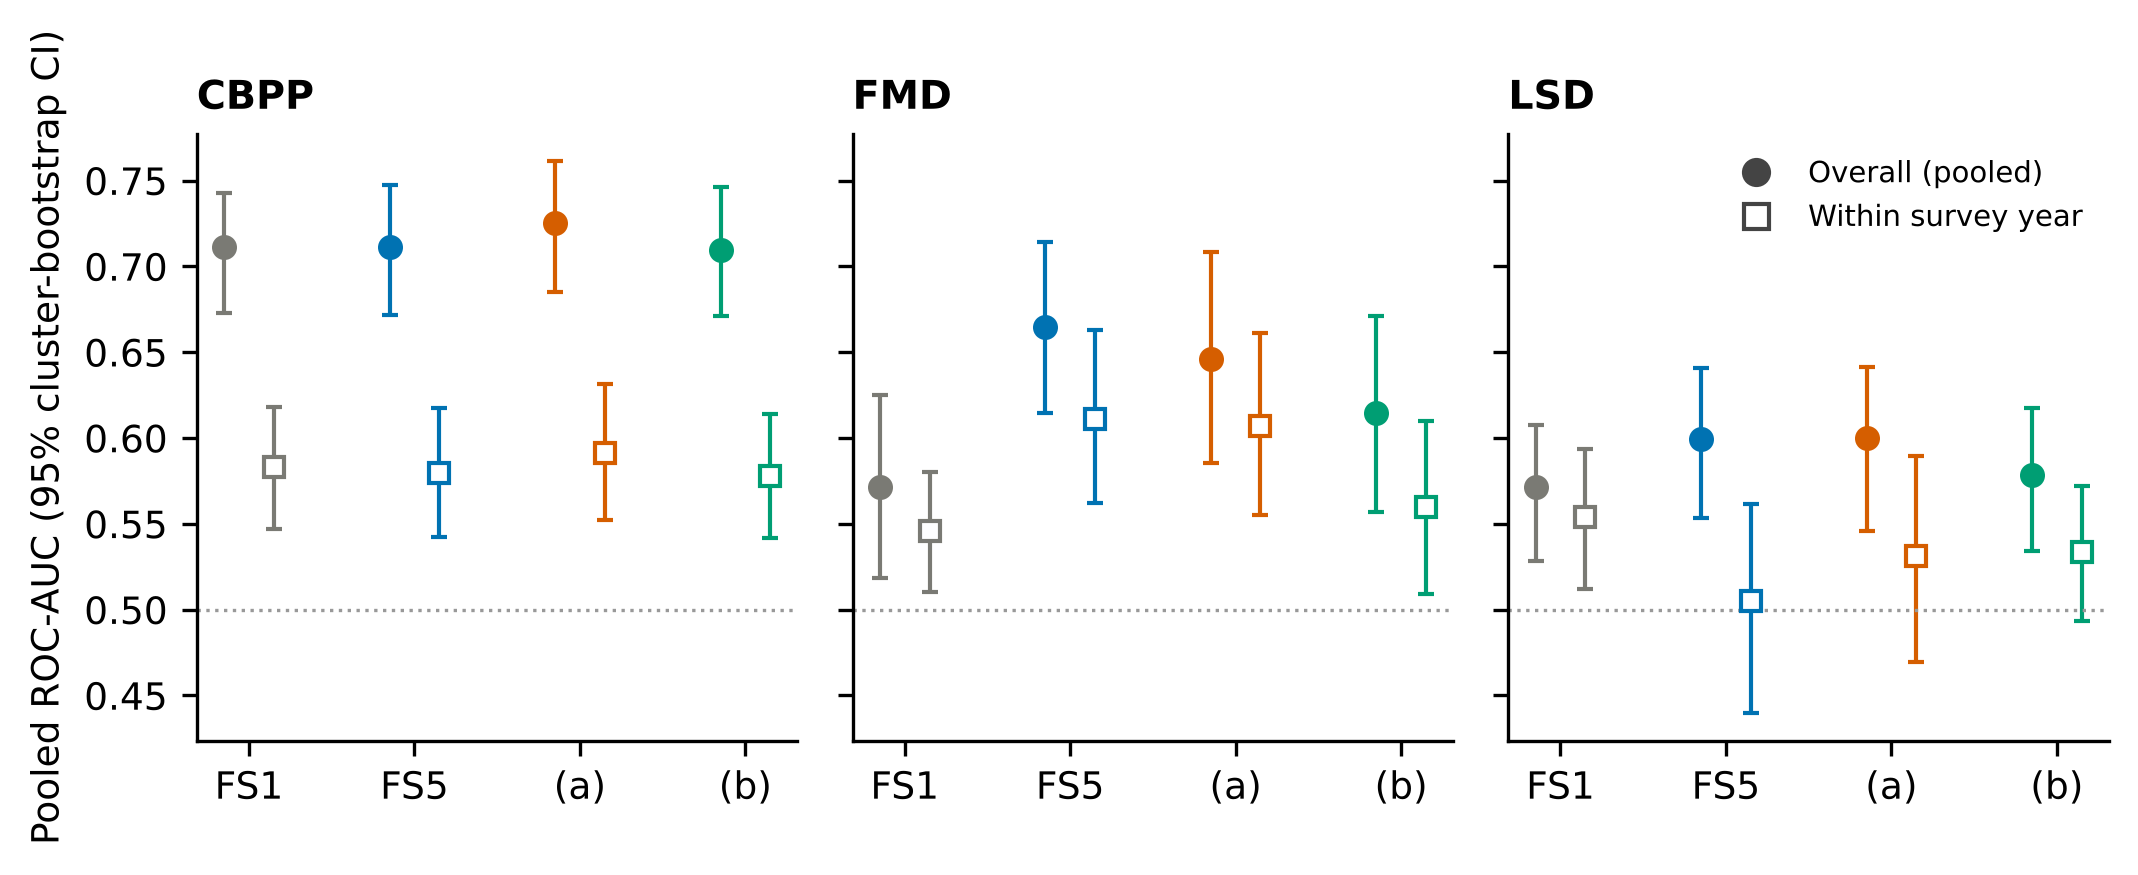

,Disease,Features,Fold x year units,"Pooled-campaign model, within-campaign AUC","Campaign-specific model, within-campaign AUC",Campaign-specific minus pooled [corrected-t 95% CI],Folds favouring campaign-specific
0,CBPP,FS1,58,0.576,0.570,"-0.006 [-0.059, +0.047]",8/15
1,CBPP,FS5,58,0.563,0.608,"+0.045 [-0.004, +0.094]",13/15
2,FMD,FS1,62,0.526,0.554,"+0.028 [-0.100, +0.157]",10/15
3,FMD,FS5,62,0.587,0.586,"-0.001 [-0.084, +0.083]",8/15
4,LSD,FS1,68,0.537,0.581,"+0.044 [-0.099, +0.188]",13/15
5,LSD,FS5,68,0.488,0.566,"+0.078 [-0.013, +0.169]",12/15


saved Fig6 v3


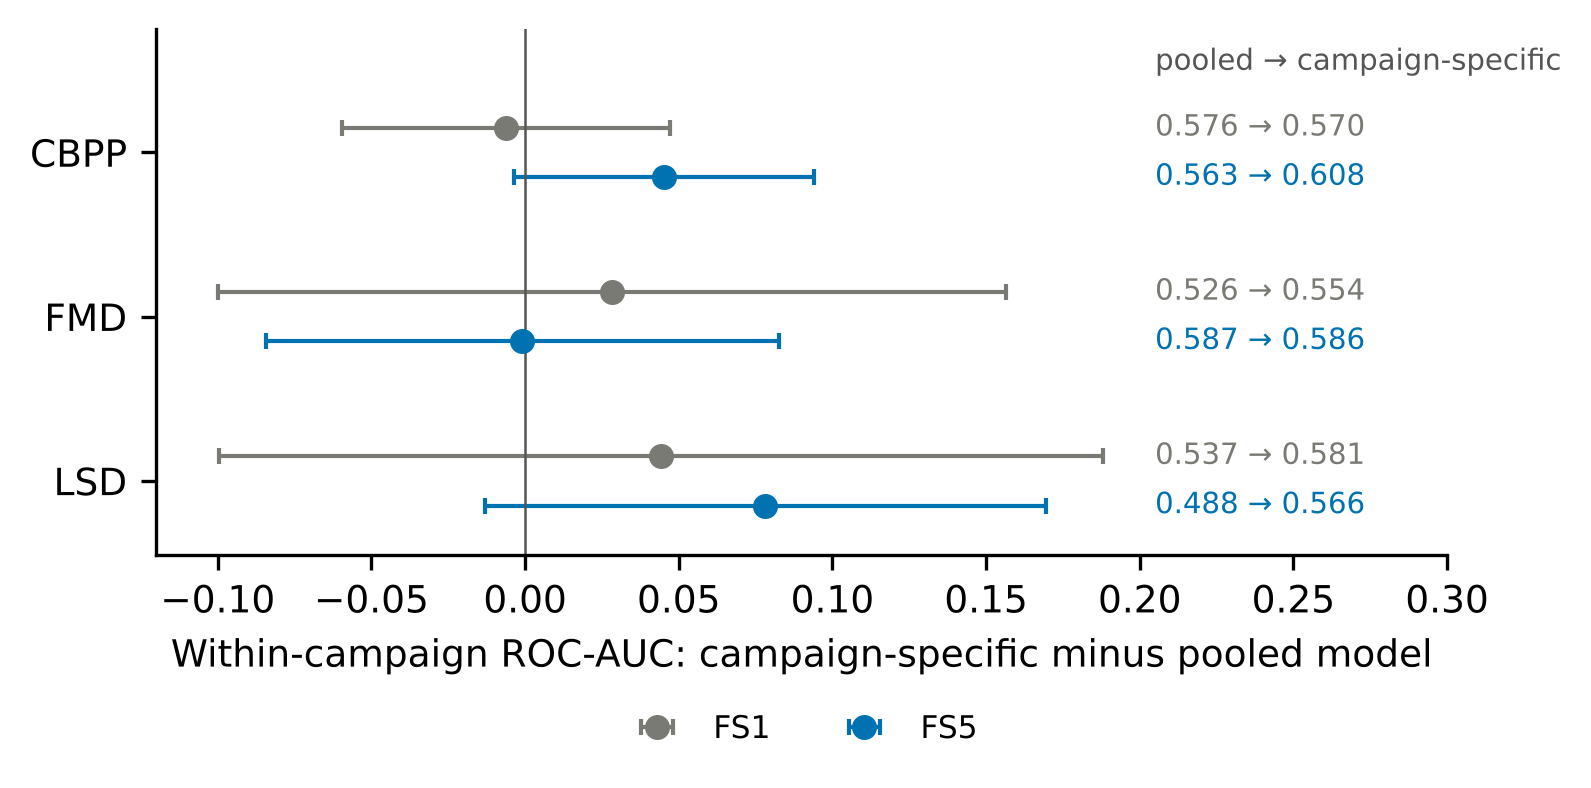

max |difference| between saved campaign predictions (E10b) and the original E10 AUCs: 1.1102230246251565e-16


,Features,Macro ROC-AUC for survey year [corrected-t 95% CI],Accuracy (5 classes),AUC 2012,AUC 2014,AUC 2015,AUC 2018,AUC 2019
0,FS1,"0.788 [0.694, 0.881]",0.580,0.826,0.779,0.797,0.855,0.649
1,Neighbourhood rates only,"0.825 [0.748, 0.903]",0.586,0.829,0.906,0.757,0.857,0.778
2,FS5,"0.868 [0.791, 0.946]",0.630,0.889,0.935,0.817,0.887,0.813


neighbourhood rates minus FS1, macro AUC for survey year [corrected-t 95% CI]: +0.038 [-0.062, +0.138], p = 0.4312
share of the 150 km kernel weight from later surveys (earlier audit, test rows, all years): 31.1%


In [18]:
display(tab(P1 / 'tables/Table5_within_year_performance_v1.csv')); show('Fig3_overall_vs_within_year_AUC_v1')
CT = RA.table_campaign_models(); display(RA.TABLES['Campaign vs pooled models']); runpy.run_path('src/paper1/rev_figures_v3.py', run_name='__main__'); show('Fig6_campaign_specific_vs_pooled_v3')
print('max |difference| between saved campaign predictions (E10b) and the original E10 AUCs:', RV.check_e10b())
CI, diff = RV.campaign_identification(); display(CI); print('neighbourhood rates minus FS1, macro AUC for survey year [corrected-t 95%% CI]: %+.3f [%+.3f, %+.3f], p = %.4f' % diff)
LS = tab(ROOT / 'results/audit_v1/A7/A7_later_survey_share_summary_v1.csv'); print('share of the 150 km kernel weight from later surveys (earlier audit, test rows, all years): %.1f%%' % (100 * LS[(LS.rows == 'test') & (LS.survey_year == 'all')].later_share_kernel150_weight.iloc[0]))

## 19. Temporal validation
Train 2012-2015 (1,564 households), test 2018-2019 (1,776). This is the closest test to forecasting; poor results are reported as they are.

,Disease,Features,Train households (2012-2015),Test households (2018-2019),Train prevalence,Test prevalence,ROC-AUC [95% CI],PR-AUC (no-skill)
0,CBPP,FS1,1564,1776,0.389,0.079,"0.383 [0.306, 0.456]",0.058 (0.079)
1,CBPP,FS5,1564,1776,0.389,0.079,"0.437 [0.354, 0.525]",0.068 (0.079)
2,FMD,FS1,1564,1776,0.241,0.132,"0.420 [0.307, 0.542]",0.110 (0.132)
3,FMD,FS5,1564,1776,0.241,0.132,"0.416 [0.287, 0.573]",0.112 (0.132)
4,LSD,FS1,1564,1776,0.244,0.206,"0.352 [0.239, 0.494]",0.178 (0.206)
5,LSD,FS5,1564,1776,0.244,0.206,"0.353 [0.249, 0.491]",0.164 (0.206)


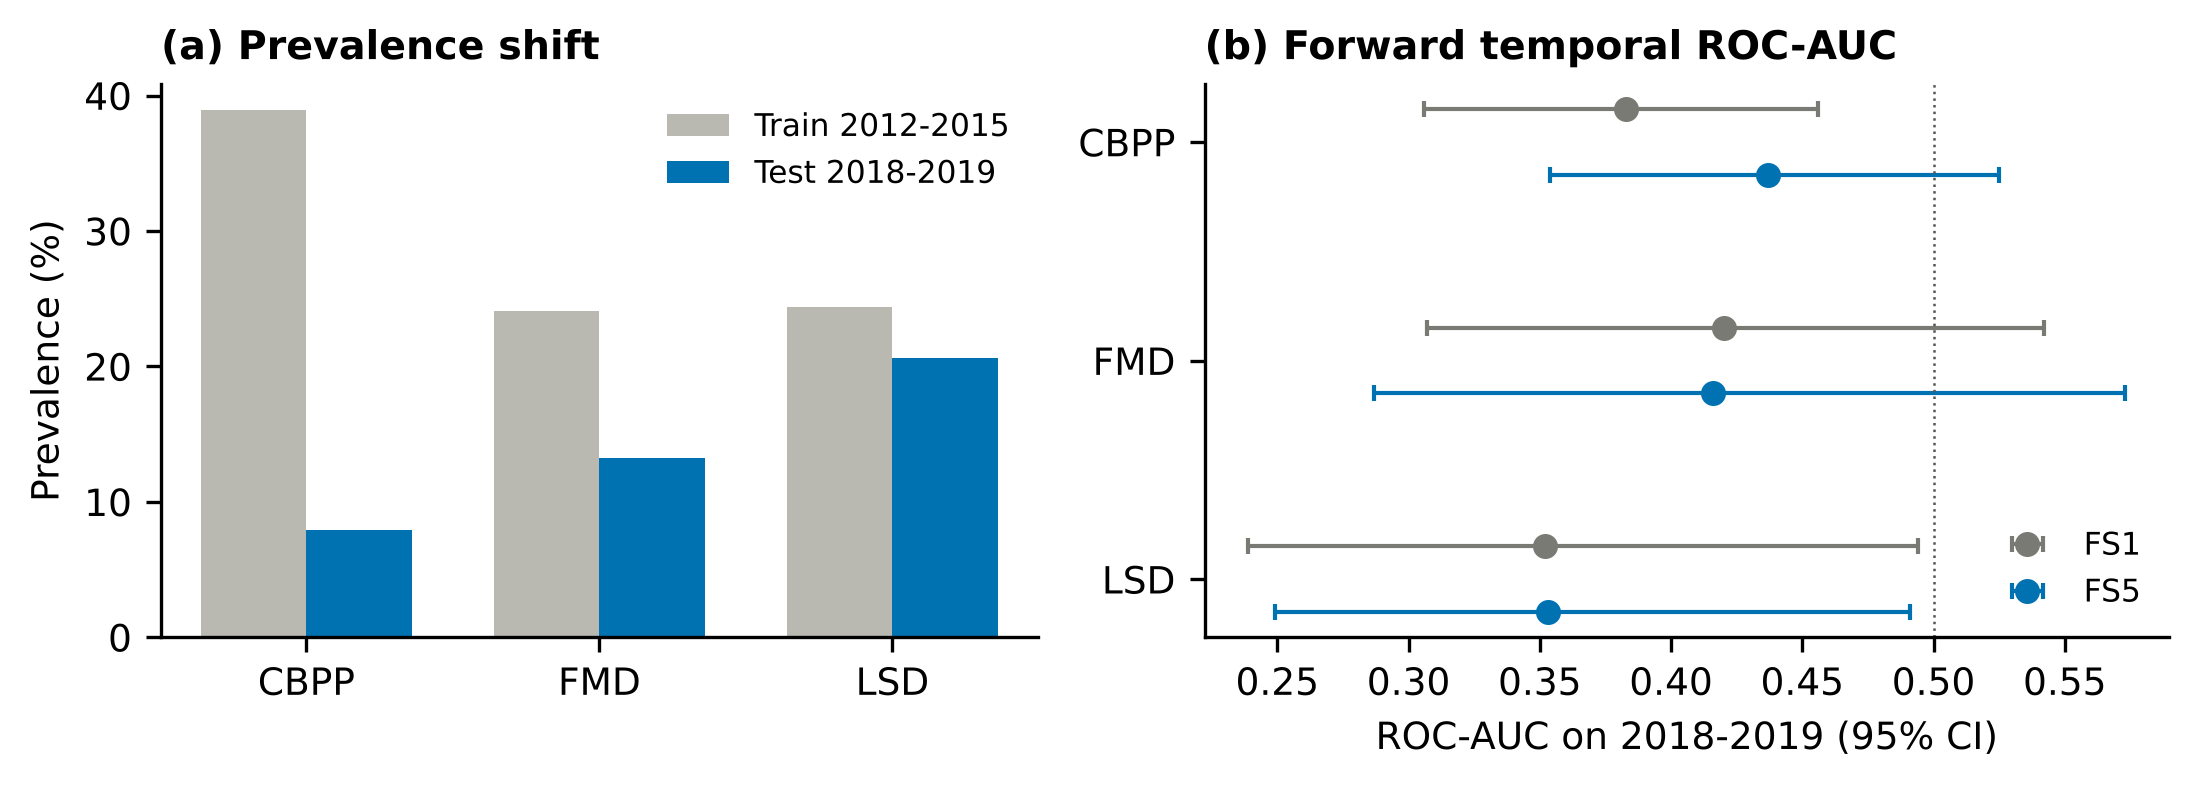

In [19]:
display(tab(P1 / 'tables/Table12_forward_temporal_validation_v1.csv')); RA.fig_temporal(); show('Fig8_forward_temporal_v1')

## 20. Statistical testing
Corrected resampled t-test (overlapping training sets across folds), location-cluster bootstrap (households in the same location are not independent), Holm correction, and permutation negative controls that rebuild the whole pipeline. The second cell recomputes every reported statistic with independent code.

,Comparison,Disease,Overall: fold mean [corrected-t 95% CI],Overall: folds > 0,Overall: pooled [bootstrap 95% CI],Within-year: fold mean [corrected-t 95% CI],Within-year: folds > 0,Within-year: pooled [bootstrap 95% CI],Overall: Holm p,Within-year: Holm p
0,FS5 minus FS1,CBPP,"+0.003 [-0.034, +0.041]",8/15,"+0.001 [-0.022, +0.022]","-0.013 [-0.074, +0.047]",5/15,"-0.004 [-0.028, +0.021]",0.858,0.733
1,FS5 minus FS1,FMD,"+0.100 [+0.025, +0.175]",14/15,"+0.093 [+0.057, +0.126]","+0.060 [-0.046, +0.165]",11/15,"+0.066 [+0.011, +0.117]",0.039,0.732
2,FS5 minus FS1,LSD,"+0.031 [-0.039, +0.102]",9/15,"+0.028 [-0.007, +0.066]","-0.049 [-0.161, +0.063]",4/15,"-0.049 [-0.115, +0.007]",0.711,0.733
3,(a) Rank average minus FS5,CBPP,"+0.005 [-0.023, +0.033]",8/15,"+0.013 [+0.003, +0.024]","+0.011 [-0.025, +0.047]",8/15,"+0.012 [-0.001, +0.026]",1.000,1.000
4,(a) Rank average minus FS5,FMD,"-0.015 [-0.061, +0.031]",4/15,"-0.019 [-0.037, -0.002]","-0.004 [-0.057, +0.049]",8/15,"-0.004 [-0.025, +0.015]",1.000,1.000
5,(a) Rank average minus FS5,LSD,"-0.006 [-0.058, +0.046]",7/15,"+0.000 [-0.023, +0.023]","+0.023 [-0.033, +0.080]",11/15,"+0.026 [+0.007, +0.046]",1.000,1.000


,Scheme,Disease,Permutations,Null FS1 ROC-AUC mean [2.5-97.5%],Null FS5 ROC-AUC mean [2.5-97.5%],Null gain mean [2.5-97.5%],Observed gain,Permutation p (resolution),Null FS5 PR-AUC,No-skill PR-AUC,Holm p (6 tests)
0,household,CBPP,100,"0.500 [0.464, 0.530]","0.504 [0.482, 0.528]","+0.003 [-0.020, +0.038]",0.018,0.198 (0.010),0.233,0.224,0.446
1,household,FMD,100,"0.501 [0.470, 0.535]","0.499 [0.472, 0.529]","-0.001 [-0.040, +0.030]",0.084,0.010 (0.010),0.189,0.183,0.059
2,household,LSD,100,"0.501 [0.473, 0.533]","0.501 [0.476, 0.527]","-0.001 [-0.028, +0.023]",0.039,0.010 (0.010),0.230,0.224,0.059
3,village,CBPP,100,"0.508 [0.450, 0.570]","0.502 [0.455, 0.560]","-0.007 [-0.071, +0.047]",0.018,0.208 (0.010),0.244,0.230,0.446
4,village,FMD,100,"0.505 [0.432, 0.575]","0.497 [0.436, 0.561]","-0.008 [-0.070, +0.052]",0.084,0.010 (0.010),0.186,0.175,0.059
5,village,LSD,100,"0.503 [0.425, 0.569]","0.499 [0.434, 0.555]","-0.004 [-0.070, +0.072]",0.039,0.149 (0.010),0.229,0.214,0.446


saved Fig5_permutation_null_v3


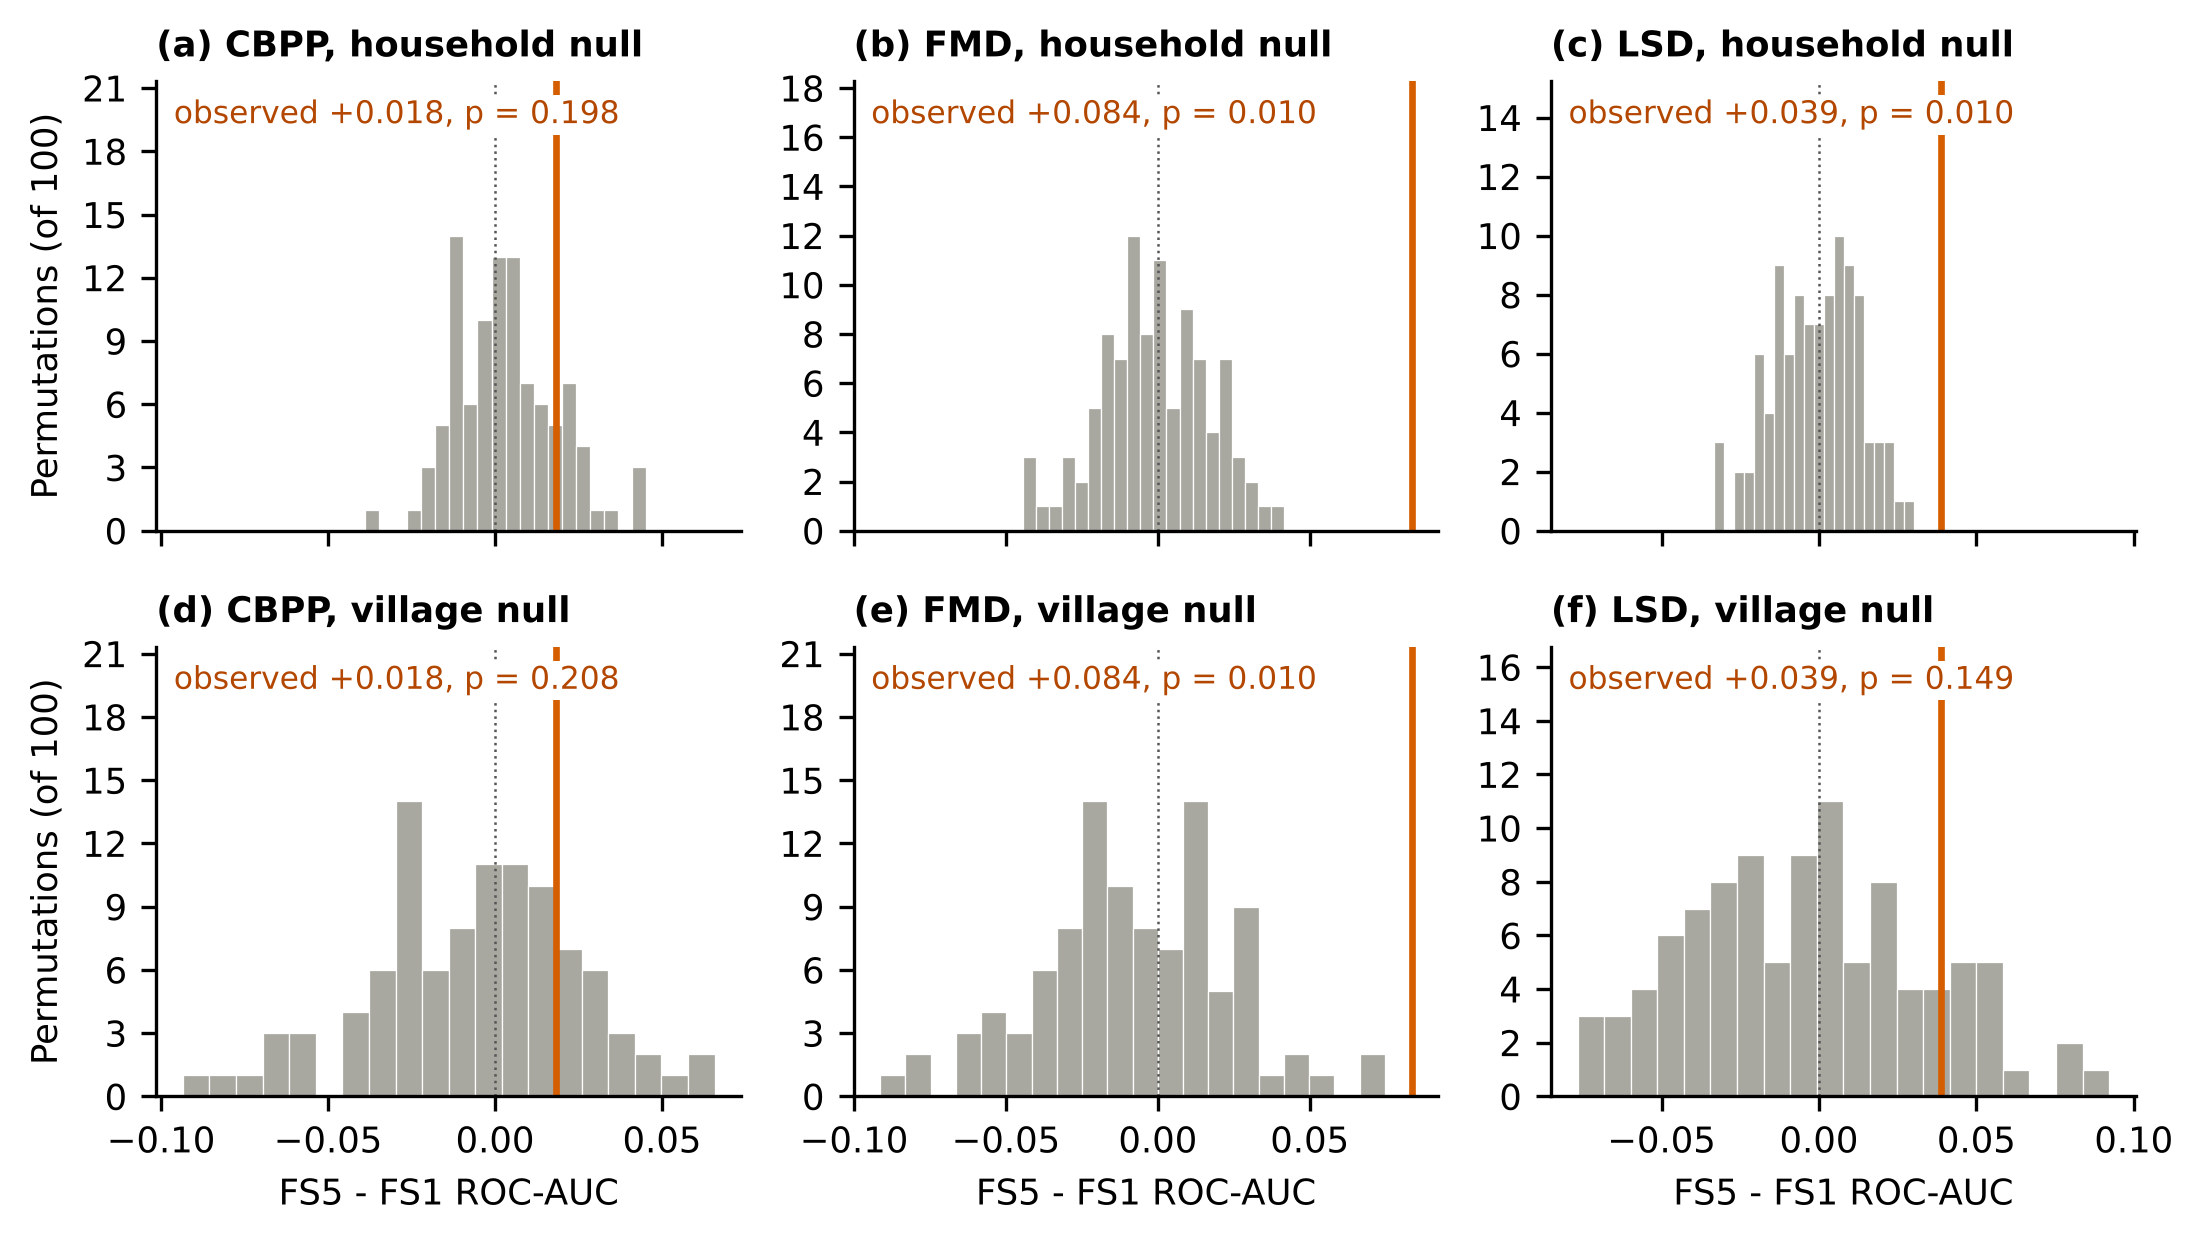

smallest attainable permutation p with 100 permutations: 1/101 = 0.0099; Holm over 6 tests multiplies the smallest p by 6: 0.0594


In [20]:
display(tab(P1 / 'tables/Table7_disease_specific_comparisons_v1.csv')); display(tab(P1 / 'tables/Table10_negative_controls_v1.csv'))
runpy.run_path('src/paper1/fig5_permutation_v3.py'); show('Fig5_permutation_null_v3')
n_perm = 100; print(f'smallest attainable permutation p with {n_perm} permutations: 1/{n_perm + 1} = {1 / (n_perm + 1):.4f}; Holm over 6 tests multiplies the smallest p by 6: {6 / (n_perm + 1):.4f}')

In [21]:
runpy.run_path('src/paper1/export_predictions_v1.py', run_name='__main__'); runpy.run_path('src/paper1/rev_verify_statistics_v1.py', run_name='__main__')
V = tab(REV / 'statistics_verification/statistics_verification_summary_v1.csv'); display(V)
check(V[V.quantity.str.contains('Table')].max_abs_difference.max() < 0.001, 'all table statistics reproduced by independent code (within rounding)')

(120240, 13) [3340]


                                                                                   quantity  max_abs_difference    n
0                                    fold-level ROC_AUC (180 fold x disease x model values)           4.651e-05  180
1                                     fold-level PR_AUC (180 fold x disease x model values)           3.797e-04  180
2                                      fold-level Brier (180 fold x disease x model values)           3.982e-08  180
3                      fold-level calibration_intercept (180 fold x disease x model values)           3.083e-06  180
4                          fold-level calibration_slope (180 fold x disease x model values)           2.229e-03  173
5                                fold-level sensitivity (180 fold x disease x model values)           1.110e-16  180
6                                fold-level specificity (180 fold x disease x model values)           1.110e-16  180
7                          fold-level balanced_accuracy (180 fol

,quantity,max_abs_difference,n
0,fold-level ROC_AUC (180 fold x disease x model values),4.651e-05,180
1,fold-level PR_AUC (180 fold x disease x model values),3.797e-04,180
2,fold-level Brier (180 fold x disease x model values),3.982e-08,180
3,fold-level calibration_intercept (180 fold x disease x m...,3.083e-06,180
4,fold-level calibration_slope (180 fold x disease x model...,2.229e-03,173
5,fold-level sensitivity (180 fold x disease x model values),1.110e-16,180
6,fold-level specificity (180 fold x disease x model values),1.110e-16,180
7,fold-level balanced_accuracy (180 fold x disease x model...,5.551e-17,180
8,fold-level F1 (180 fold x disease x model values),8.327e-17,180
9,fold-level MCC (180 fold x disease x model values),9.714e-17,180


OK - all table statistics reproduced by independent code (within rounding)


## 21. Figures and tables
All remaining figures (PNG 300 dpi and PDF).

saved Fig1_workflow_v7


saved v2 figures


saved FigS2_calibration_v2


saved FigS4_grouped_importance_v2


,scheme,Same location in training (%),Median (km),IQR (km),95th percentile (km),Test households (all folds)
0,Random 5-fold CV,96.7,0.0,0.0-0.0,0.0,3340
1,Spatial 81 km,0.0,35.1,22.2-55.6,92.9,10020
2,Spatial 120 km,0.0,49.7,31.3-70.9,121.2,10020
3,Spatial 160 km,0.0,56.7,34.8-86.0,130.7,10020
4,Spatial 81 km + 50 km buffer,0.0,71.0,59.8-89.6,127.8,10020
5,Spatial 81 km + 100 km buffer,0.0,125.4,111.2-148.3,190.3,10020


saved R2Fig1_ablation_v2, R2Fig6_train_test_distances_v2


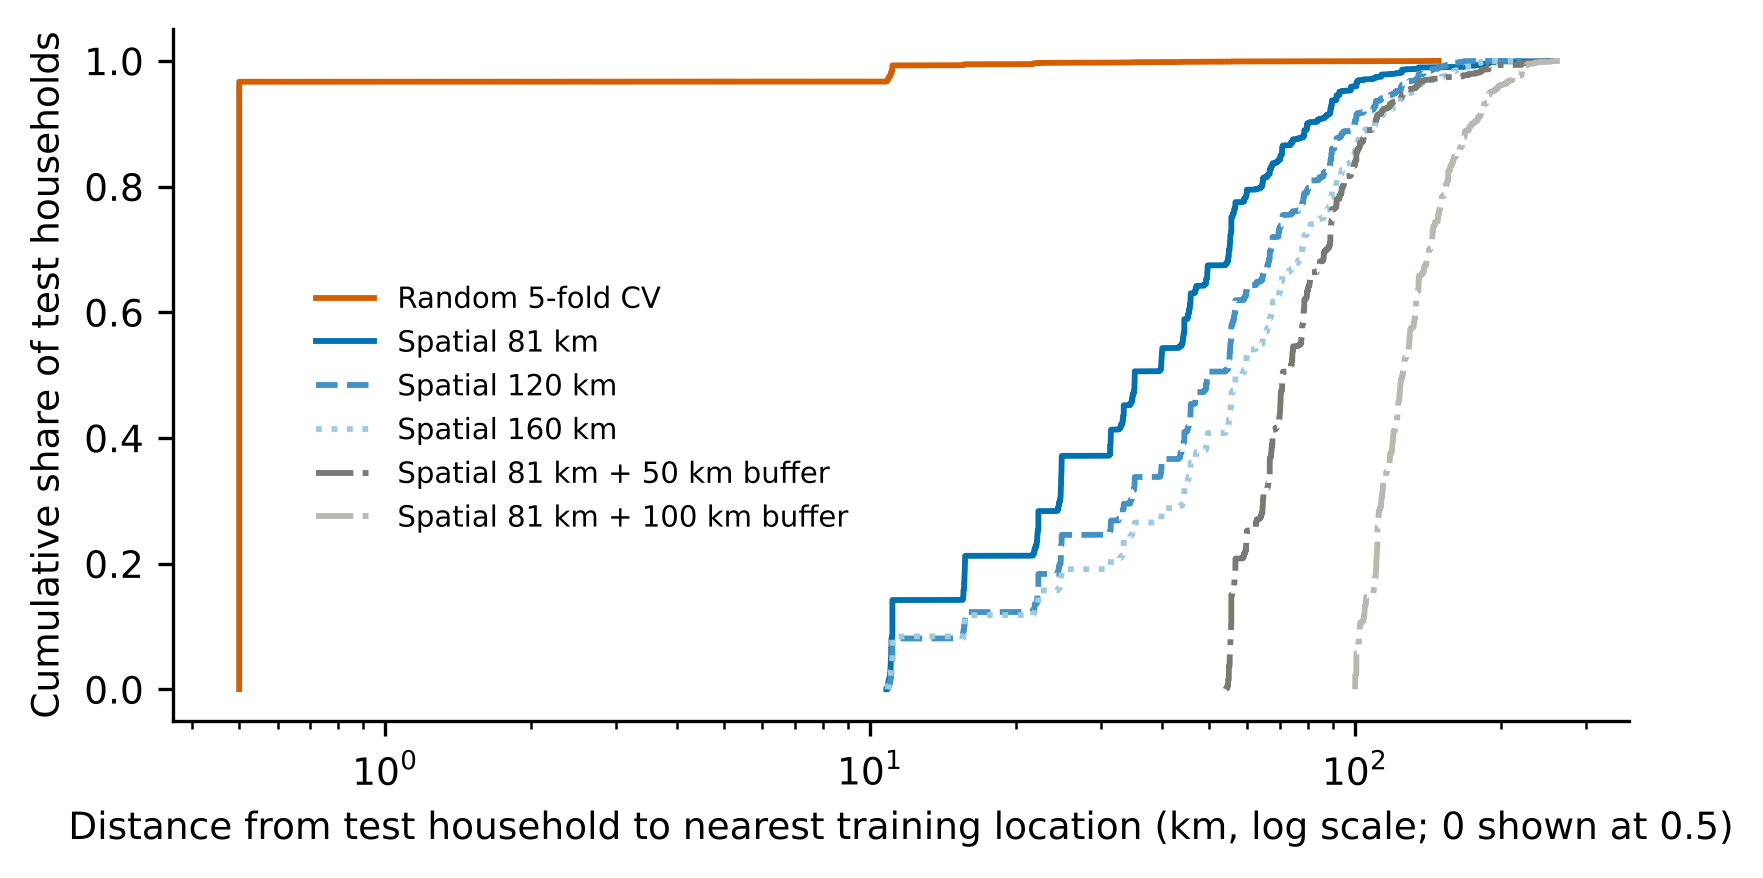

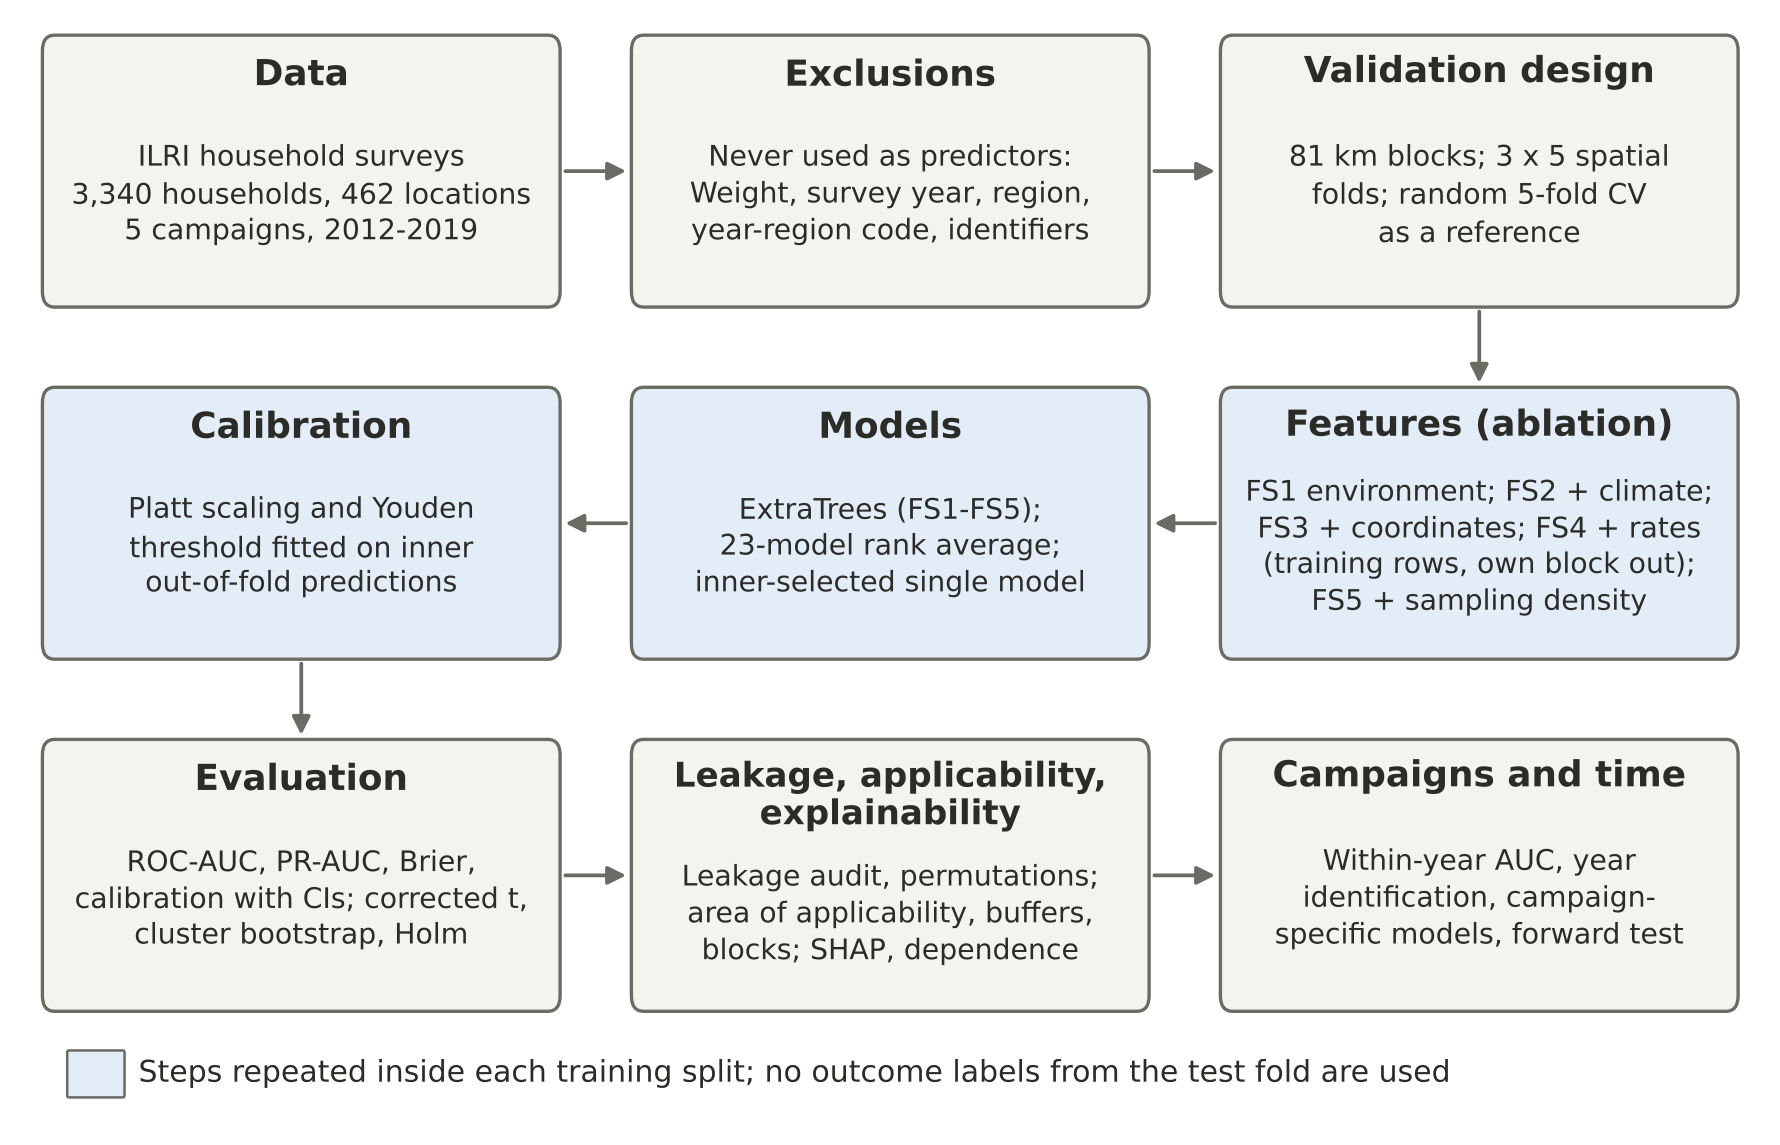

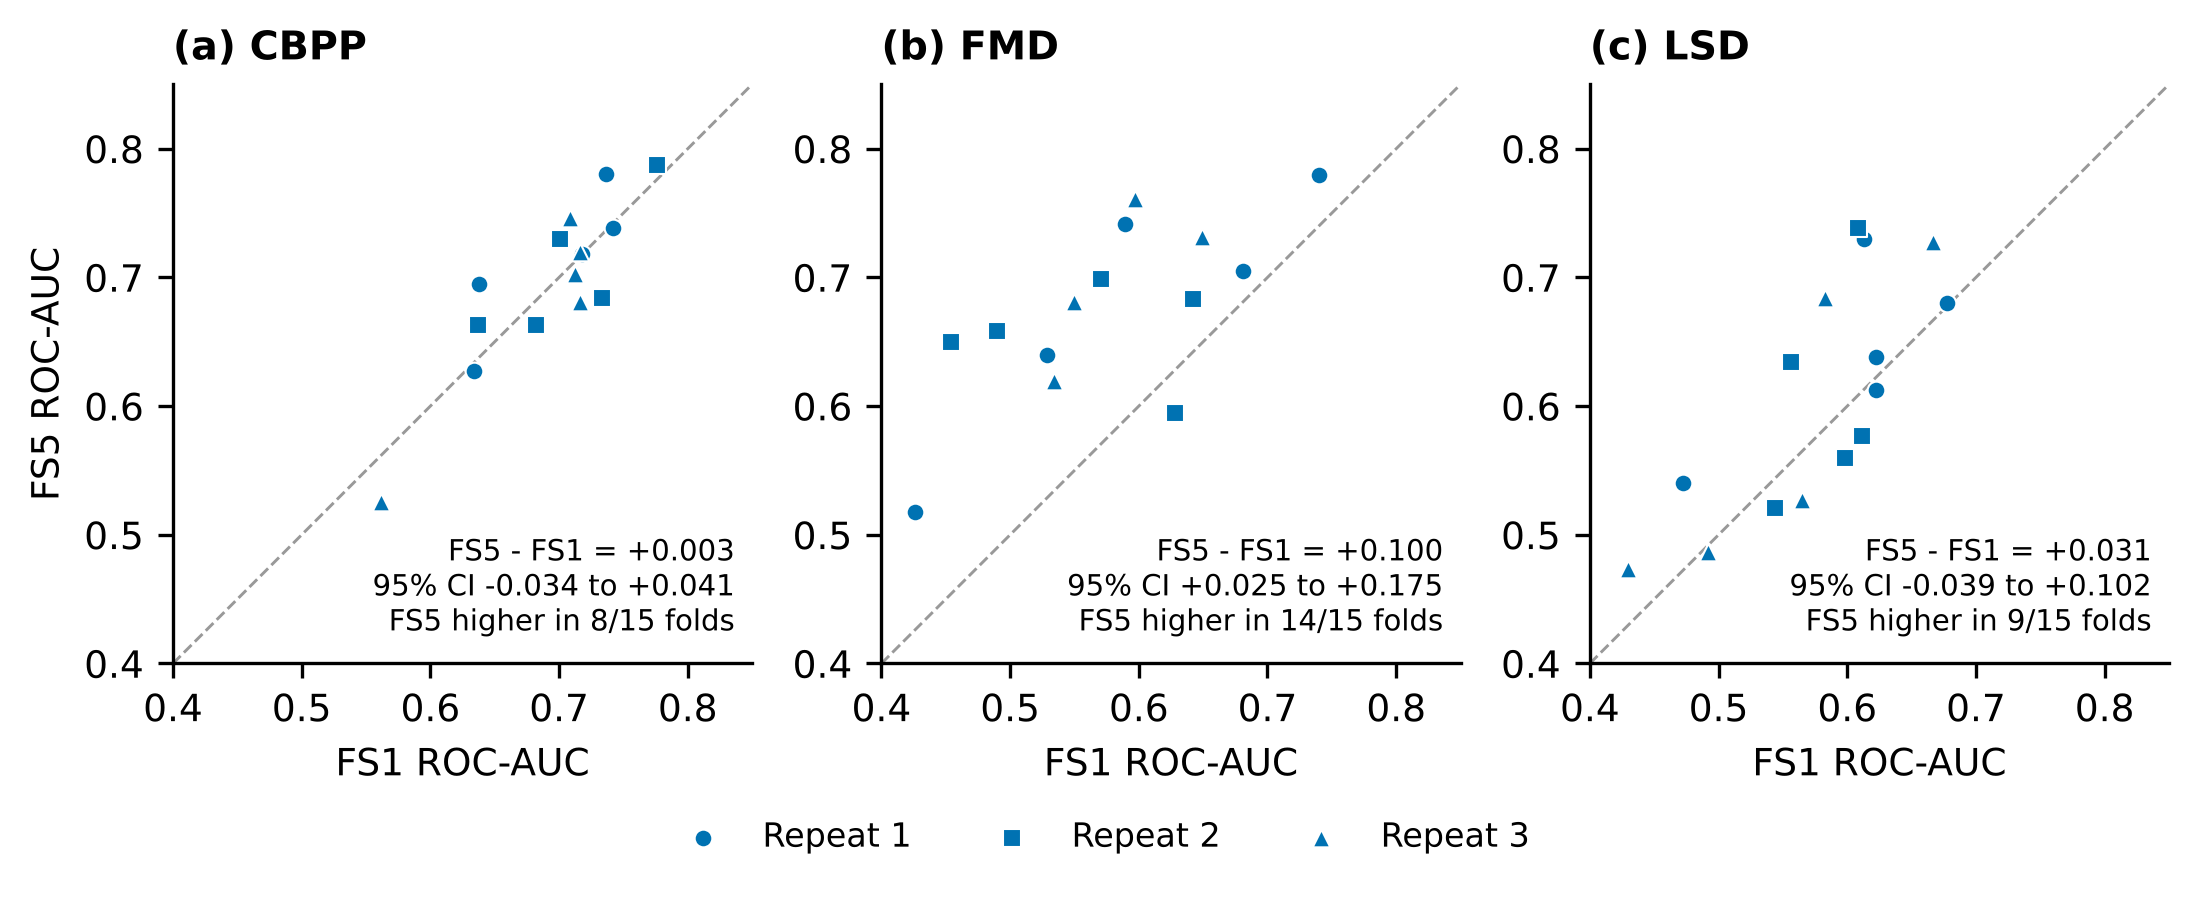

,Feature set,Added group,Variables,Added,Total,Uses outcome labels?
0,FS1,Environmental,"Altitude, temperature, precipitation, relative humidity,...",5,5,No
1,FS2,+ Climate indices,"Sea-level temperature, De Martonne index, temperature x ...",6,11,No
2,FS3,+ Coordinates,"Latitude, longitude, latitude + longitude, latitude - lo...",4,15,No
3,FS4,+ Neighbourhood and cross-disease rates,"Gaussian-kernel rates at 50, 150 and 400 km (9) and rate...",18,33,Yes (training rows only; own 81 km block excluded)
4,FS5,+ Sampling density,"Log kernel density of training households at 50, 150 and...",6,39,No (household counts and distances only)


In [22]:
runpy.run_path('src/paper1/fig1_workflow_v7.py'); runpy.run_path('src/paper1/rev_figures_v2.py', run_name='__main__'); runpy.run_path('src/paper1/figS2_calibration_v2.py'); runpy.run_path('src/paper1/figS4_importance_v2.py')
display(RV.distance_distributions()); runpy.run_path('src/paper1/rev2_figures_v2.py', run_name='__main__'); show('R2Fig6_train_test_distances_v2'); show('Fig1_workflow_v7'); show('Fig4_FS1_vs_FS5_paired_folds_v2')
display(R3.table2())   # manuscript Table 2 (nested feature sets)

## 22. Exporting final results
Fold assignments (all schemes) and household-level predictions of every experiment are written to CSV; all result tables are collected in an Excel workbook.

In [23]:
print(RR.export_all()); RA.excel_workbook()
with pd.ExcelWriter(R2 / 'tables/IJIES_Paper1_revision2_tables_v1.xlsx') as W:
    for p in sorted((R2 / 'tables').glob('*.csv')): tab(p).to_excel(W, sheet_name=p.stem[:31], index=False)
for d in (P1 / 'tables', REV / 'tables', R2 / 'tables', R2 / 'figures', R2 / 'exports'): print(d.relative_to(ROOT), len(list(d.glob('*'))), 'files')

((3340, 23), (180996, 9))
results/paper1_v1/tables 19 files
results/paper1_rev_v1/tables 4 files
results/paper1_rev2_v1/tables 14 files
results/paper1_rev2_v1/figures 20 files
results/paper1_rev2_v1/exports 2 files


## Appendix. Completed analyses reported as observed (not used in the revised analysis)
1. **Confirmatory partition (2 x 5 folds):** opened once on 2026-11-20 with the pre-correction code, for hypotheses registered just before opening.
2. **Pre-registered optimisation study:** completed before this revision and outside its scope. It is reported in Supplementary Section S2. No optimisation algorithm is used in this notebook.

In [24]:
print(json.dumps(json.load(open(ROOT / 'results/stage9_confirmatory_v1/hypothesis_results.json')), indent=1)[:900])
display(tab(ROOT / 'results/stage9_confirmatory_v1/confirmatory_summary.csv').set_index('disease').T)   # per-disease confirmatory estimates (pooled bootstrap CI and fold-level corrected-t p)

{
 "opened_at_utc": "2026-11-20T14:19:31+00:00",
 "H1_per_disease_CI_above_0": {
  "FMD": true,
  "LSD": false
 },
 "H1_confirmed": false,
 "H1_CBPP_exploratory": {
  "H1 FS5 - FS1: pooled": 0.011496965158117045,
  "H1 FS5 - FS1: CI_lo": -0.008295001454008383,
  "H1 FS5 - FS1: CI_hi": 0.03253076709026211
 },
 "H2_FS5_minus_a": {
  "CBPP": {
   "pooled": -0.010950239733940714,
   "CI_lo": -0.02171666435040521,
   "CI_hi": 0.00020076519573871372
  },
  "FMD": {
   "pooled": 0.003380973828413847,
   "CI_lo": -0.008822602708983409,
   "CI_hi": 0.016019758031566196
  },
  "LSD": {
   "pooled": -0.023499061163022028,
   "CI_lo": -0.04367456946205853,
   "CI_hi": -0.00548218459404392
  }
 },
 "runtime_min": 20.5
}


disease,CBPP,FMD,LSD
FS1 confirmatory,0.684,0.577,0.569
FS5 confirmatory,0.699,0.649,0.588
(a) confirmatory,0.7,0.637,0.592
FS1 development,0.694,0.563,0.577
FS5 development,0.697,0.665,0.613
(a) development,0.702,0.647,0.604
H1 FS5 - FS1: pooled,0.011,0.068,0.008
H1 FS5 - FS1: CI_lo,-0.008,0.03,-0.028
H1 FS5 - FS1: CI_hi,0.033,0.104,0.044
H1 FS5 - FS1: mean of folds,0.015,0.072,0.019
